In [ ]:
# Generic imports
import pandas as pd
import numpy as np
import torch
from tqdm.auto import tqdm
from transformers import pipeline
import matplotlib.pyplot as plt
import os
import math

# Addresses
datasets_address = "datasets"
emotions_address = "datasets/emotions"
emotions_plots_address = "plots/emotions"
emotions_normal_plots_address = "plots/emotions/normal"
emotions_wt_plots_address = "plots/emotions/weighted"
BERT_topics_address = "topics/BERTopic"
louvain_topics_address = "topics/louvain"

# Parameters
possible_emotions = ["anger", "fear", "pessimism", "joy", "trust", "optimism"]
dimensions = [20, 10]
# List of possible colors -> https://matplotlib.org/stable/gallery/color/named_colors.html
colors = {"anger": 'firebrick', "fear": 'purple', "pessimism": 'darkblue', "joy": 'gold', "trust": 'cyan', "optimism": 'limegreen'}
markers = {"anger": 'o', "fear": 's', "pessimism": 'v', "joy": '*', "trust": 'D', "optimism": 'h'}

c:\Users\giaco\Documents\python_environments\Network-Science\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
designers_comments = pd.read_csv(f"{datasets_address}/designers.csv")
programmers_comments = pd.read_csv(f"{datasets_address}/programmers.csv")

print(f"Designers comments: {designers_comments.shape[0]}")
print(f"Programmers comments: {programmers_comments.shape[0]}")

Designers comments: 17856
Programmers comments: 18320


# Extract emotions
From the translated clean text, we need to extract emotions using the [Hugging Face RoBERTa model](https://huggingface.co/cardiffnlp/twitter-roberta-large-emotion-latest).

In [ ]:
def emotion_extractor(df):
  # use GPU
  device = torch.device('cuda:0')

  # define the pipeline for emotion extractor (if needed)
  pipe = pipeline('text-classification',
                  model = "cardiffnlp/twitter-roberta-large-emotion-latest",
                  top_k = None,
                  truncation = True,
                  device = device,
                  batch_size = 4)

  # get emotions
  for i in tqdm(range(len(df))):
    text = df.loc[i,'translated_clean']
    # obtain predictions with scores for each emotion
    predictions = pipe(text)[0]
    for j in range(len(predictions)):
      df.loc[i, predictions[j]['label']] = round(predictions[j]['score'],4)

  return df

In [ ]:
def emotions_means(df, emotions, frequency, weighted):
  # copy to not modify the original dataframe
  df = df.copy()

  # obtain the month related to each month
  df['date'] = pd.to_datetime(df['date'])
  df['month'] = df['date'].dt.to_period(freq = frequency).astype(str)

  # calculate the weighted means (if requested)
  if weighted:
    weighted_upvotes = np.log1p(np.abs(df.upvotes))
    weighted_sum = df[emotions].mul(abs(weighted_upvotes), axis=0).groupby(df['month']).sum()
    weight_totals = df.upvotes.groupby(df['month']).sum()
    monthly_mean = weighted_sum.div(weight_totals, axis=0)
  # calculate the non-weighted means
  else:
    # group by the string column and compute means
    monthly_mean = df.groupby('month').mean(numeric_only = True)

  return monthly_mean

In [ ]:
def plot_emotions(address, df, emotions, name, colors, markers, extra = ""):
  plt.figure(figsize = dimensions)
  plt.xlabel('Quarter')
  plt.ylabel('Mean Score')
  plt.title(f'Mean emotions score over quarters (2020 - 2025) - {name}{extra}')

  plt.ylim([0, 1])
  plt.xticks(rotation=45)
  plt.yticks(np.arange(0, 1, 0.1))

  for e in emotions:
    plt.plot(df.index, df[e], label = e, marker = markers[e], color = colors[e])

  plt.legend(title = "emotions")
  plt.savefig(f"{address}/{name}_emotions.png")
  plt.show()

# Emotions for designers and programmers

In [ ]:
designers_emotions = emotion_extractor(designers_comments)
programmers_emotions = emotion_extractor(programmers_comments)

In [ ]:
# save to CSVs
if not os.path.exists(emotions_address):
    os.makedirs(emotions_address)

designers_emotions.to_csv(f"{emotions_address}/designers_emotions.csv", index=False)
programmers_emotions.to_csv(f"{emotions_address}/programmers_emotions.csv", index=False)

## Emotion means
We can calculate the emotion means and plot them all in one graph to compare them. We do this for all datasets (designers, programmers and both combined).

In [ ]:
designers_emotions = pd.read_csv(f"{emotions_address}/designers_emotions.csv")
programmers_emotions = pd.read_csv(f"{emotions_address}/programmers_emotions.csv")
all_emotions = pd.concat([designers_emotions, programmers_emotions])

In [ ]:
# find out if upvotes are correlated to any emotion
for e in possible_emotions:
  emotion_corr = designers_emotions[e].corr(abs(designers_emotions["upvotes"]))
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.05017915462607419
Upvotes to fear correlation: -0.010937241562587395
Upvotes to pessimism correlation: 0.010747161747682614
Upvotes to joy correlation: -0.021113424714994486
Upvotes to trust correlation: -0.028547945318874973
Upvotes to optimism correlation: -0.04311695227145843


In [ ]:
# find out if upvotes are correlated to any emotion
for e in possible_emotions:
  emotion_corr = programmers_emotions[e].corr(abs(programmers_emotions["upvotes"]))
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.042954138168221544
Upvotes to fear correlation: 0.0067739842648175865
Upvotes to pessimism correlation: 0.01836086390032106
Upvotes to joy correlation: -0.013751056500804104
Upvotes to trust correlation: -0.03321393924605971
Upvotes to optimism correlation: -0.027741373752999846


In [ ]:
# find out if upvotes are correlated to any emotion
for e in possible_emotions:
  emotion_corr = all_emotions[e].corr(abs(all_emotions["upvotes"]))
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.048845286307404916
Upvotes to fear correlation: -0.0013240484220338204
Upvotes to pessimism correlation: 0.015721984525992622
Upvotes to joy correlation: -0.023796441536427716
Upvotes to trust correlation: -0.034803574321991534
Upvotes to optimism correlation: -0.04072124229785079


We can see that the emotions are not significantly correlated to the quantity of upvotes.

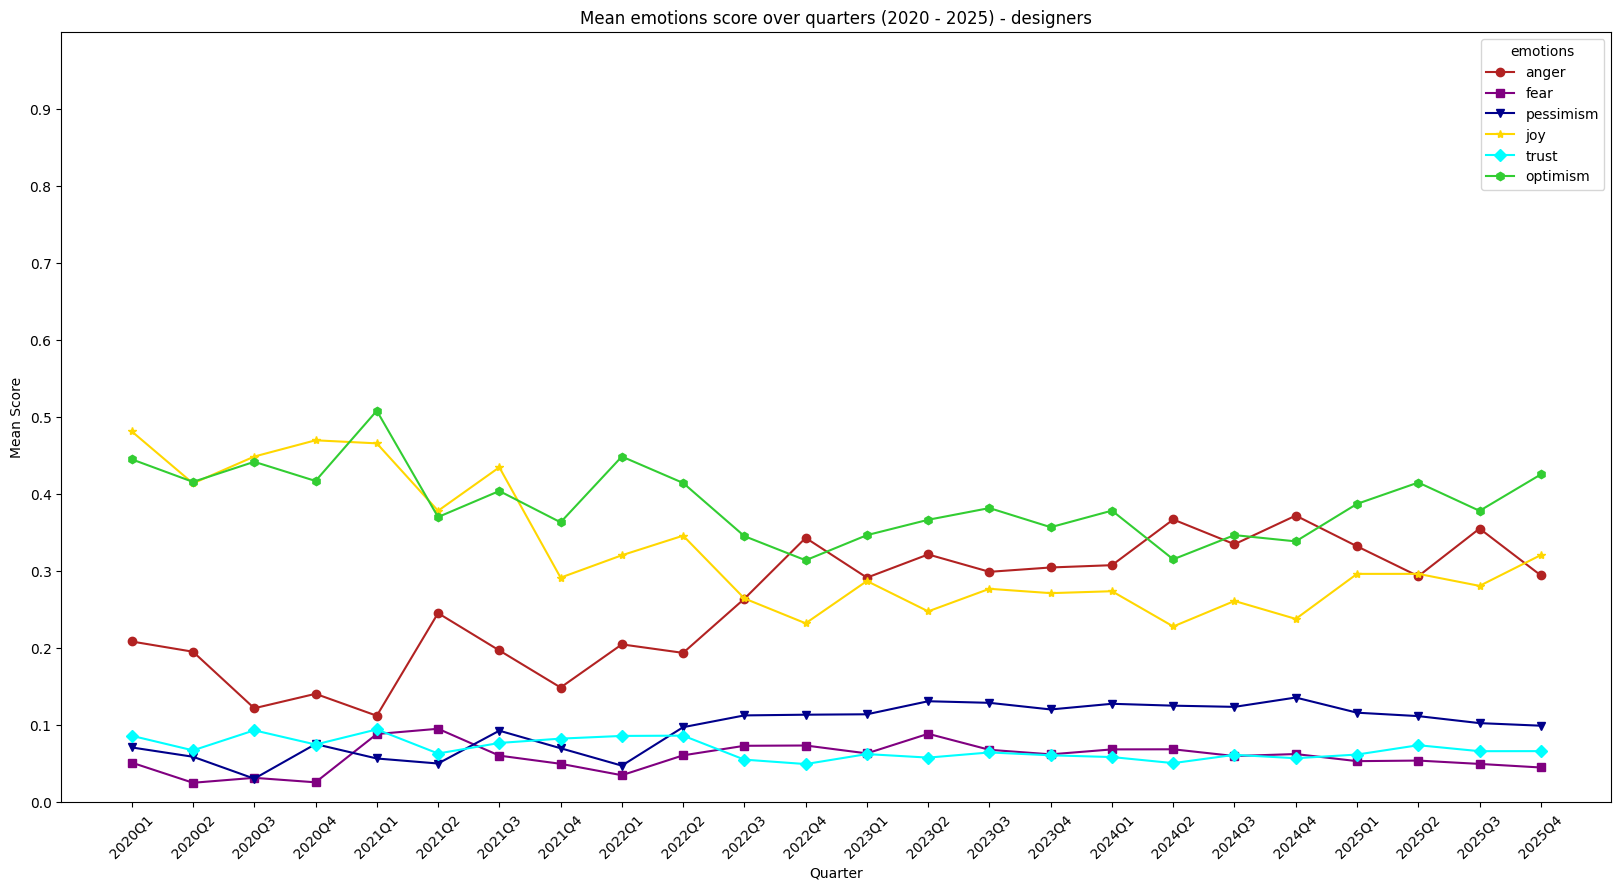

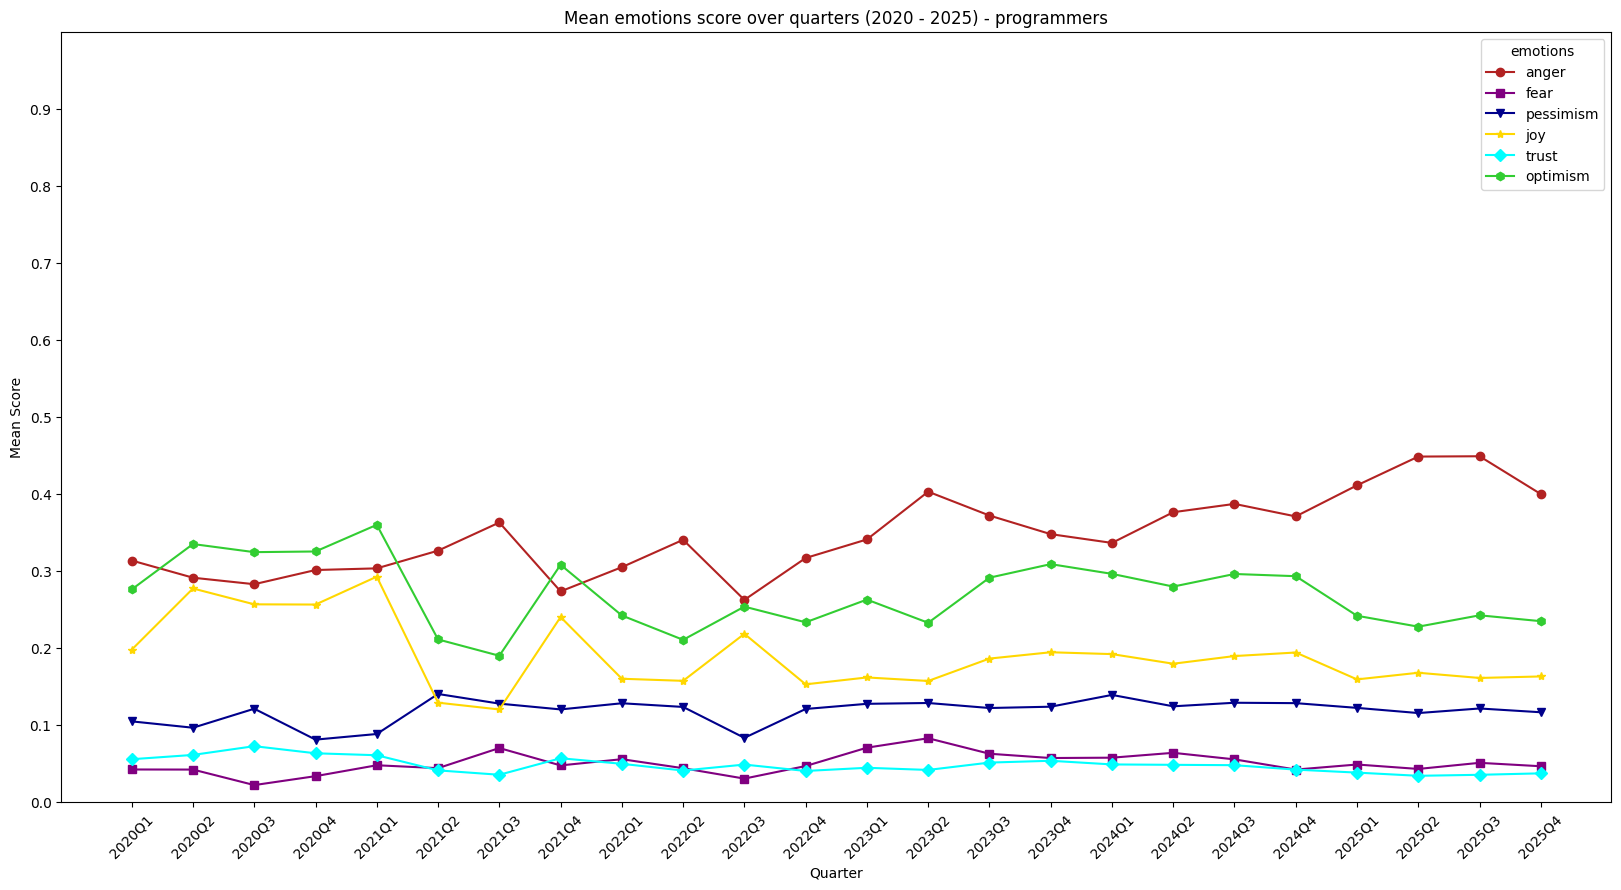

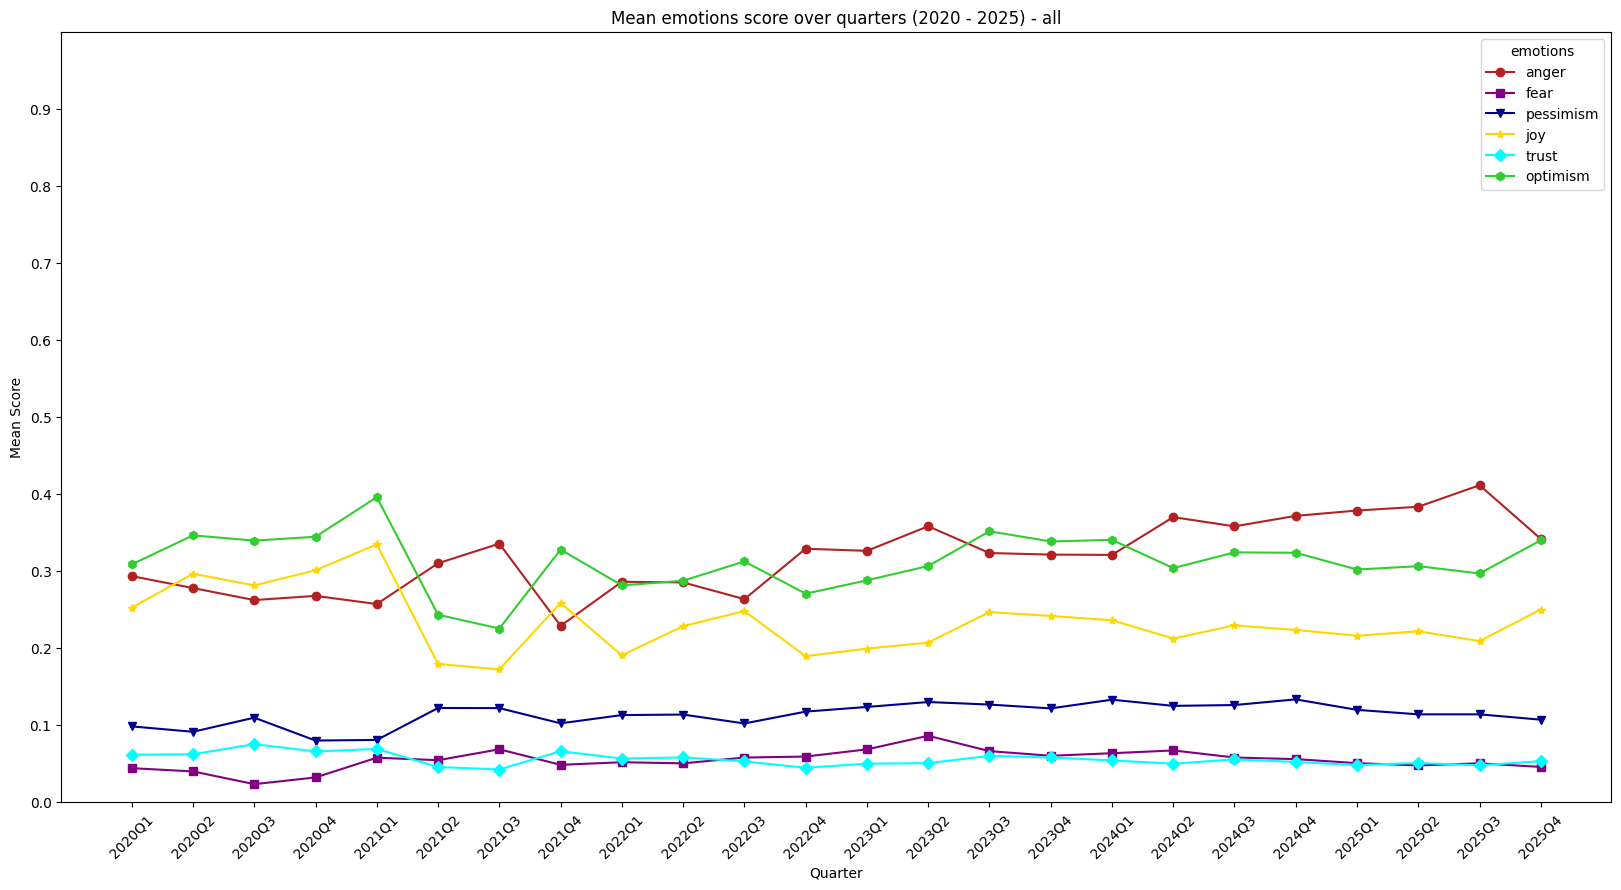

In [ ]:
if not os.path.exists(emotions_plots_address):
    os.makedirs(emotions_plots_address)

if not os.path.exists(emotions_normal_plots_address):
    os.makedirs(emotions_normal_plots_address)

if not os.path.exists(emotions_wt_plots_address):
    os.makedirs(emotions_wt_plots_address)

designers_emotion_means = emotions_means(designers_emotions, possible_emotions, 'Q', False)
plot_emotions(emotions_normal_plots_address, designers_emotion_means, possible_emotions, "designers", colors, markers)

programmers_emotion_means = emotions_means(programmers_emotions, possible_emotions, 'Q', False)
plot_emotions(emotions_normal_plots_address, programmers_emotion_means, possible_emotions, "programmers", colors, markers)

all_emotion_means = emotions_means(all_emotions, possible_emotions, 'Q', False)
plot_emotions(emotions_normal_plots_address, all_emotion_means, possible_emotions, "all", colors, markers)

In [ ]:
for e in possible_emotions:
  emotion_corr = designers_emotion_means['upvotes'].corr(designers_emotion_means[e])
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.6133162112103371
Upvotes to fear correlation: 0.0706395994605879
Upvotes to pessimism correlation: 0.4814409792039356
Upvotes to joy correlation: -0.43251254259189087
Upvotes to trust correlation: -0.4145685755262331
Upvotes to optimism correlation: -0.3522392042344773


In [ ]:
for e in possible_emotions:
  emotion_corr = programmers_emotion_means['upvotes'].corr(programmers_emotion_means[e])
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.19000505314362703
Upvotes to fear correlation: -0.0739382272408981
Upvotes to pessimism correlation: 0.22986112261120606
Upvotes to joy correlation: -0.4024820560322667
Upvotes to trust correlation: -0.42101582896765316
Upvotes to optimism correlation: -0.514569269628215


In [ ]:
for e in possible_emotions:
  emotion_corr = all_emotion_means['upvotes'].corr(all_emotion_means[e])
  print(f"Upvotes to {e} correlation: {emotion_corr}")

Upvotes to anger correlation: 0.2609345209148958
Upvotes to fear correlation: -0.13982696350228677
Upvotes to pessimism correlation: 0.04935980379729217
Upvotes to joy correlation: -0.4294969268846515
Upvotes to trust correlation: -0.4271896023148677
Upvotes to optimism correlation: -0.5615291265913971


We can also calculate weighted emotions means, with the weight being the quantity of upvotes, and plot them for all datasets.

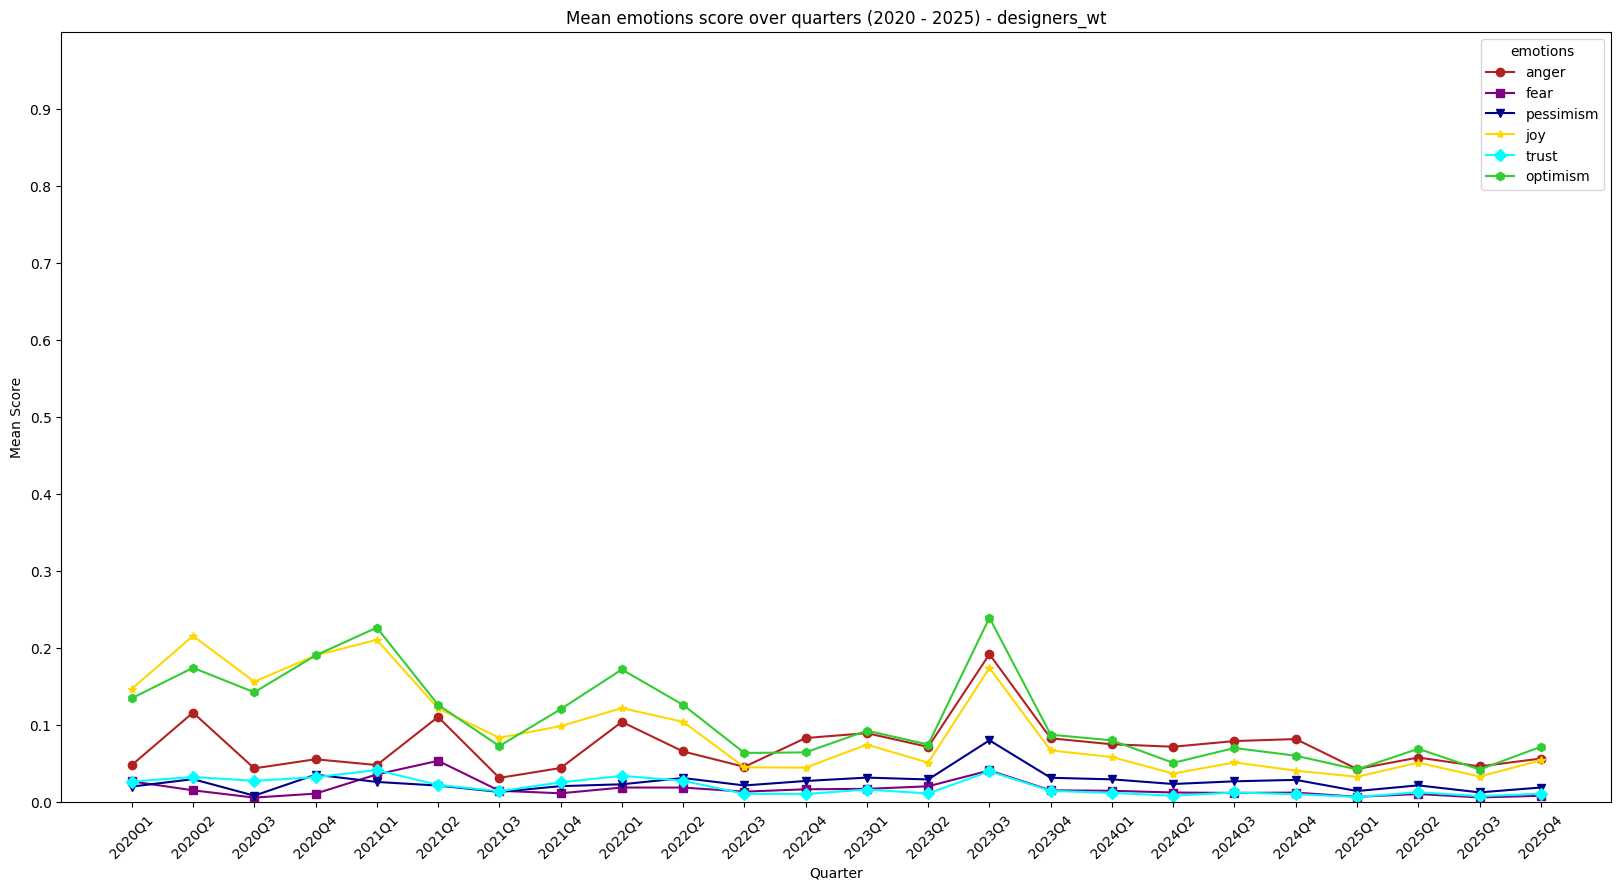

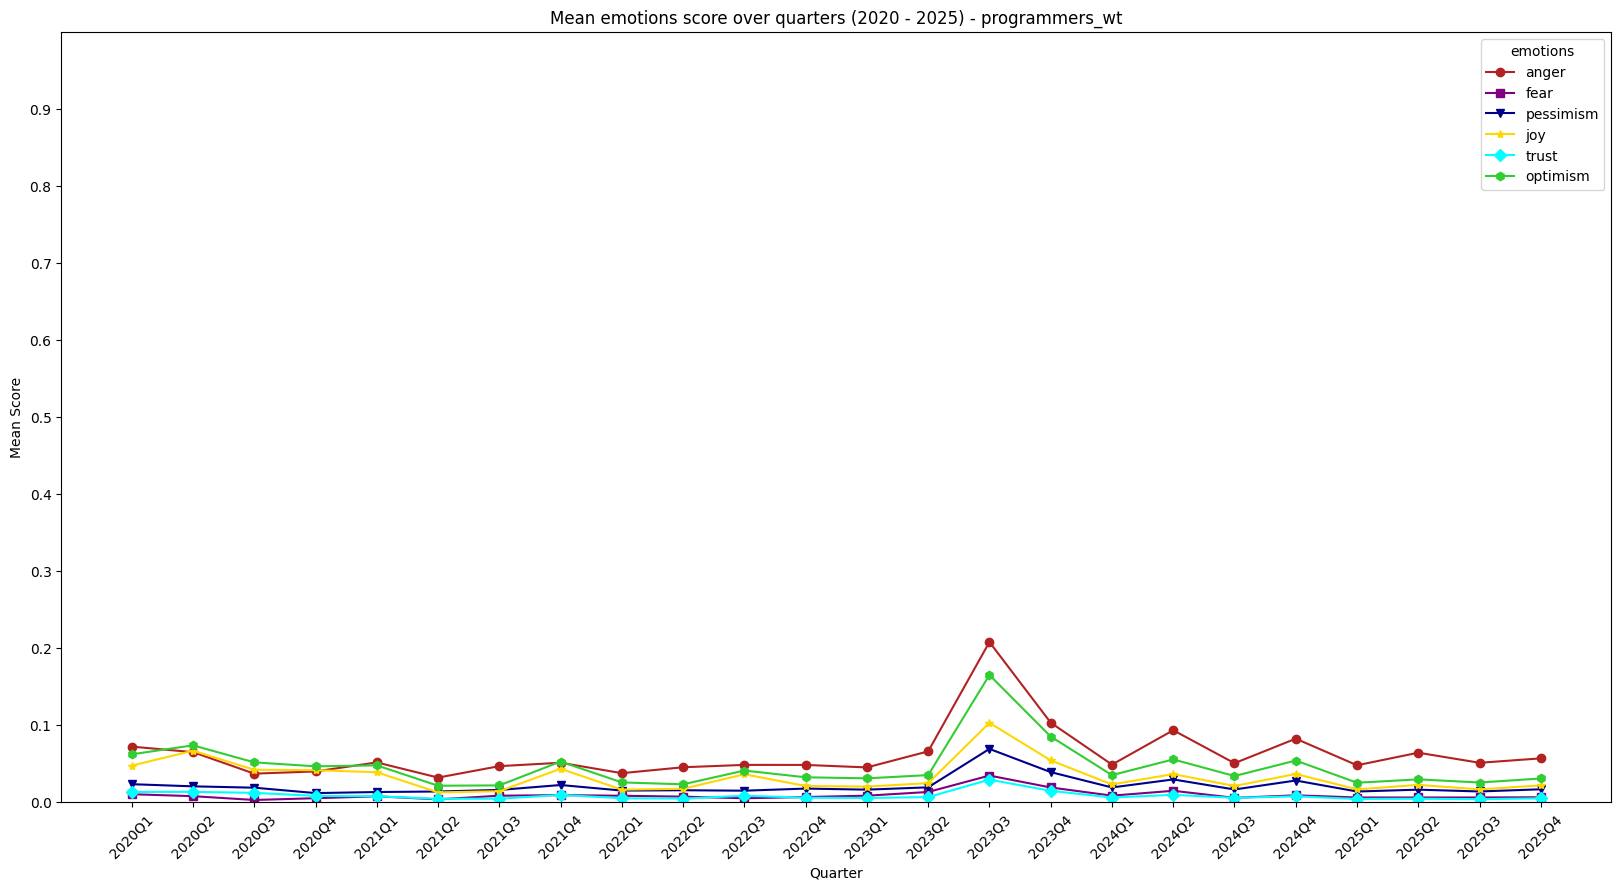

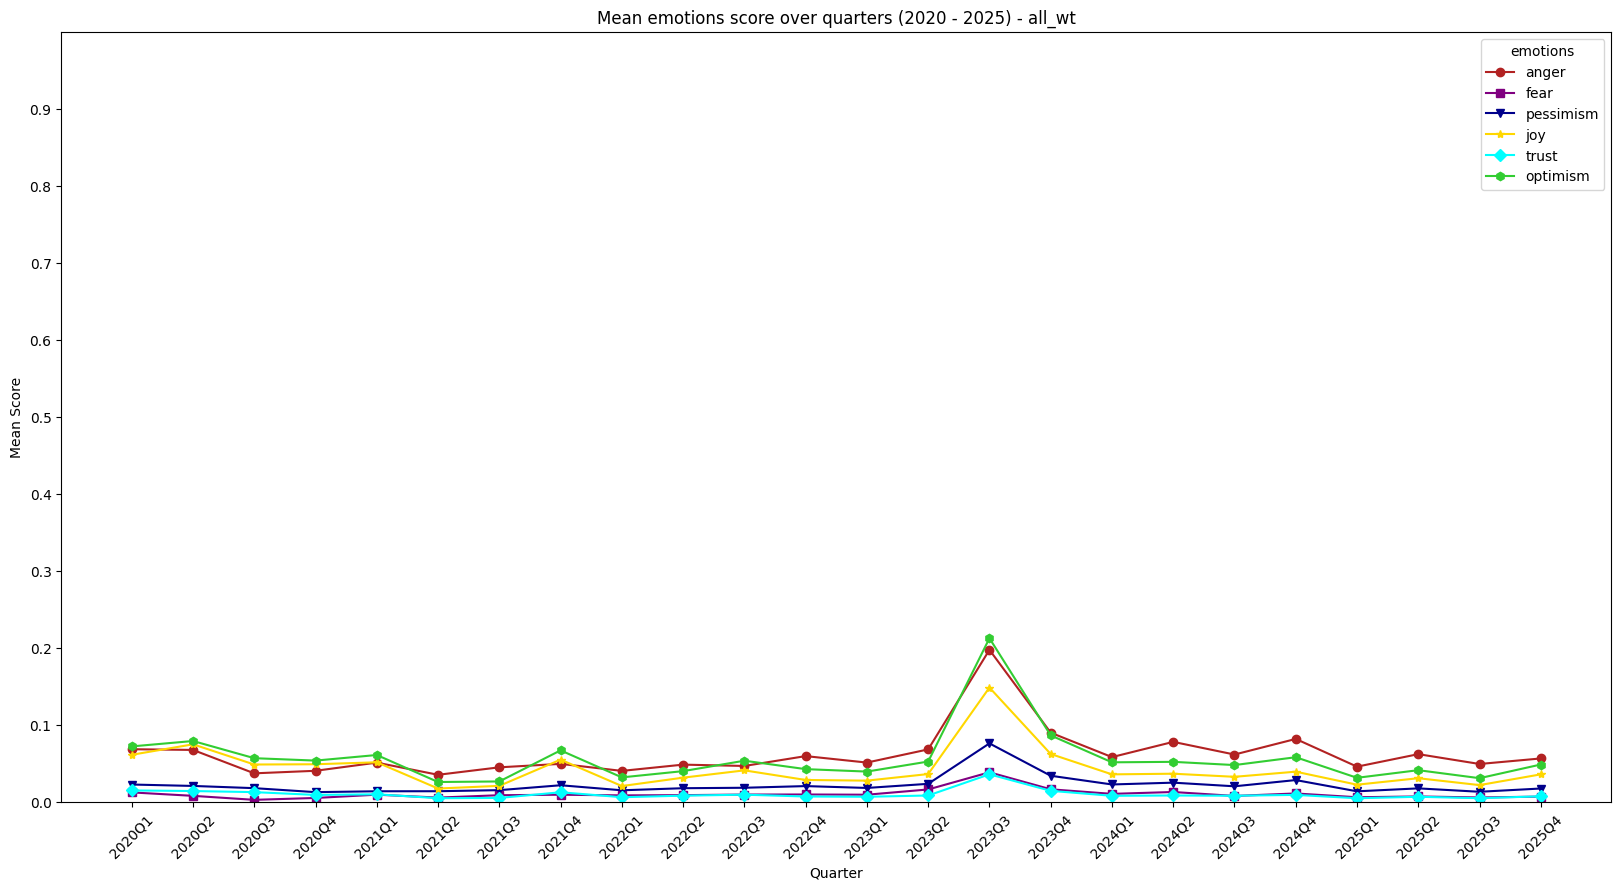

In [ ]:
designers_emotion_wt_means = emotions_means(designers_emotions, possible_emotions, 'Q', True)
plot_emotions(emotions_wt_plots_address, designers_emotion_wt_means, possible_emotions, "designers_wt", colors, markers)

programmers_emotion_wt_means = emotions_means(programmers_emotions, possible_emotions, 'Q', True)
plot_emotions(emotions_wt_plots_address, programmers_emotion_wt_means, possible_emotions, "programmers_wt", colors, markers)

all_emotion_wt_means = emotions_means(all_emotions, possible_emotions, 'Q', True)
plot_emotions(emotions_wt_plots_address, all_emotion_wt_means, possible_emotions, "all_wt", colors, markers)

# Topics' emotions

## Topics from BERTopic

In [ ]:
designers_topics = pd.read_csv(f"{BERT_topics_address}/C_designers.csv")
programmers_topics = pd.read_csv(f"{BERT_topics_address}/C_programmers.csv")

print(f"Designers topics: {designers_topics.shape[1]}")
print(f"Programmers topics: {programmers_topics.shape[1]}")

Designers topics: 8
Programmers topics: 65


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

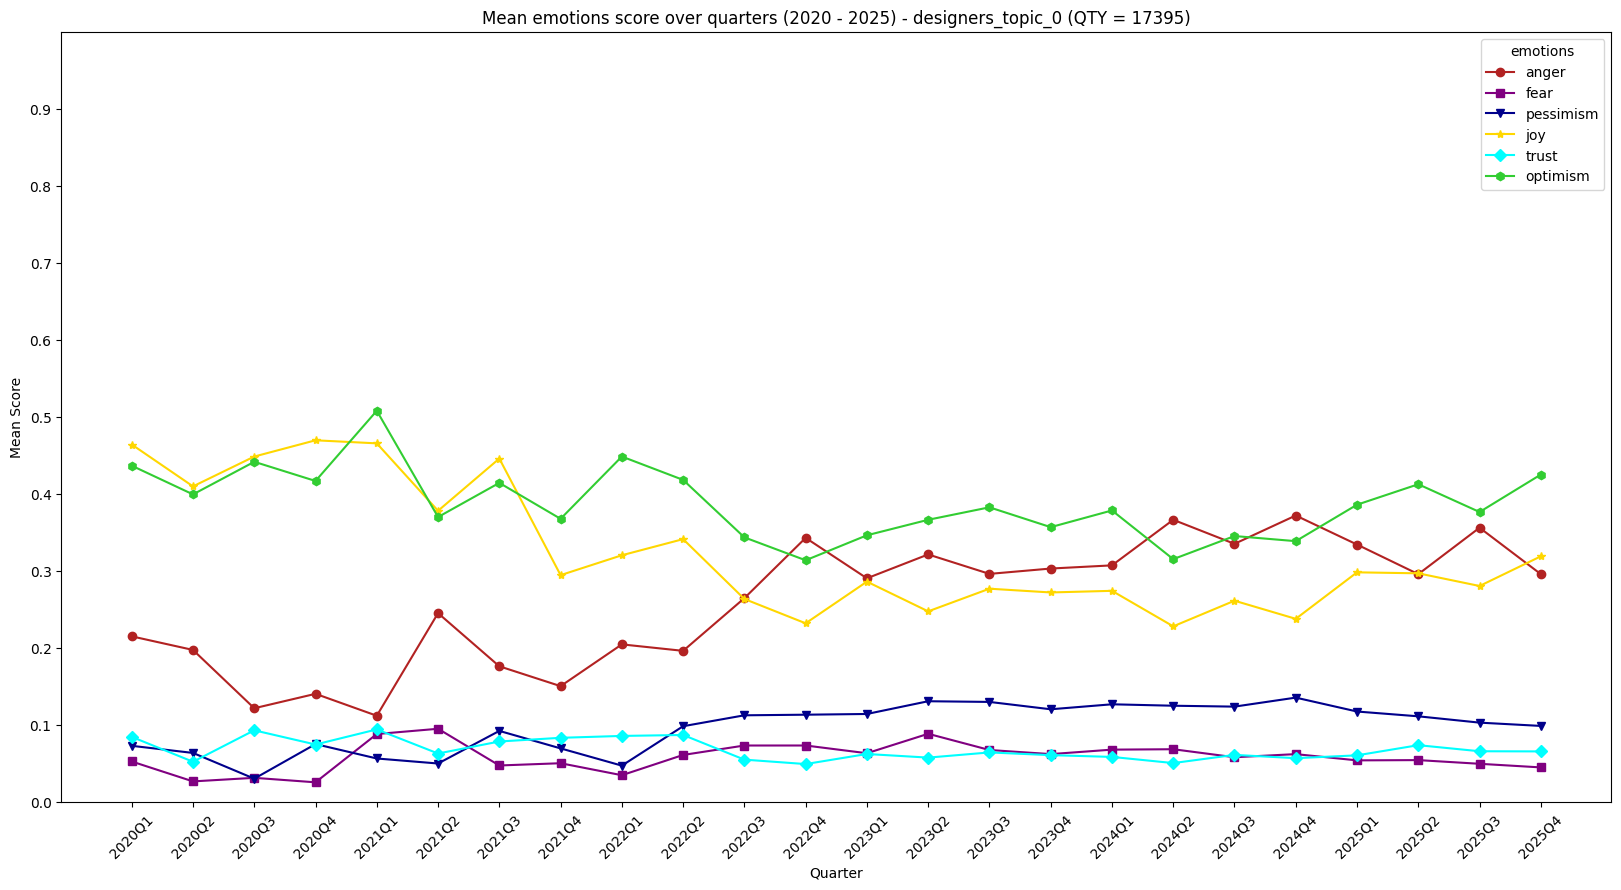

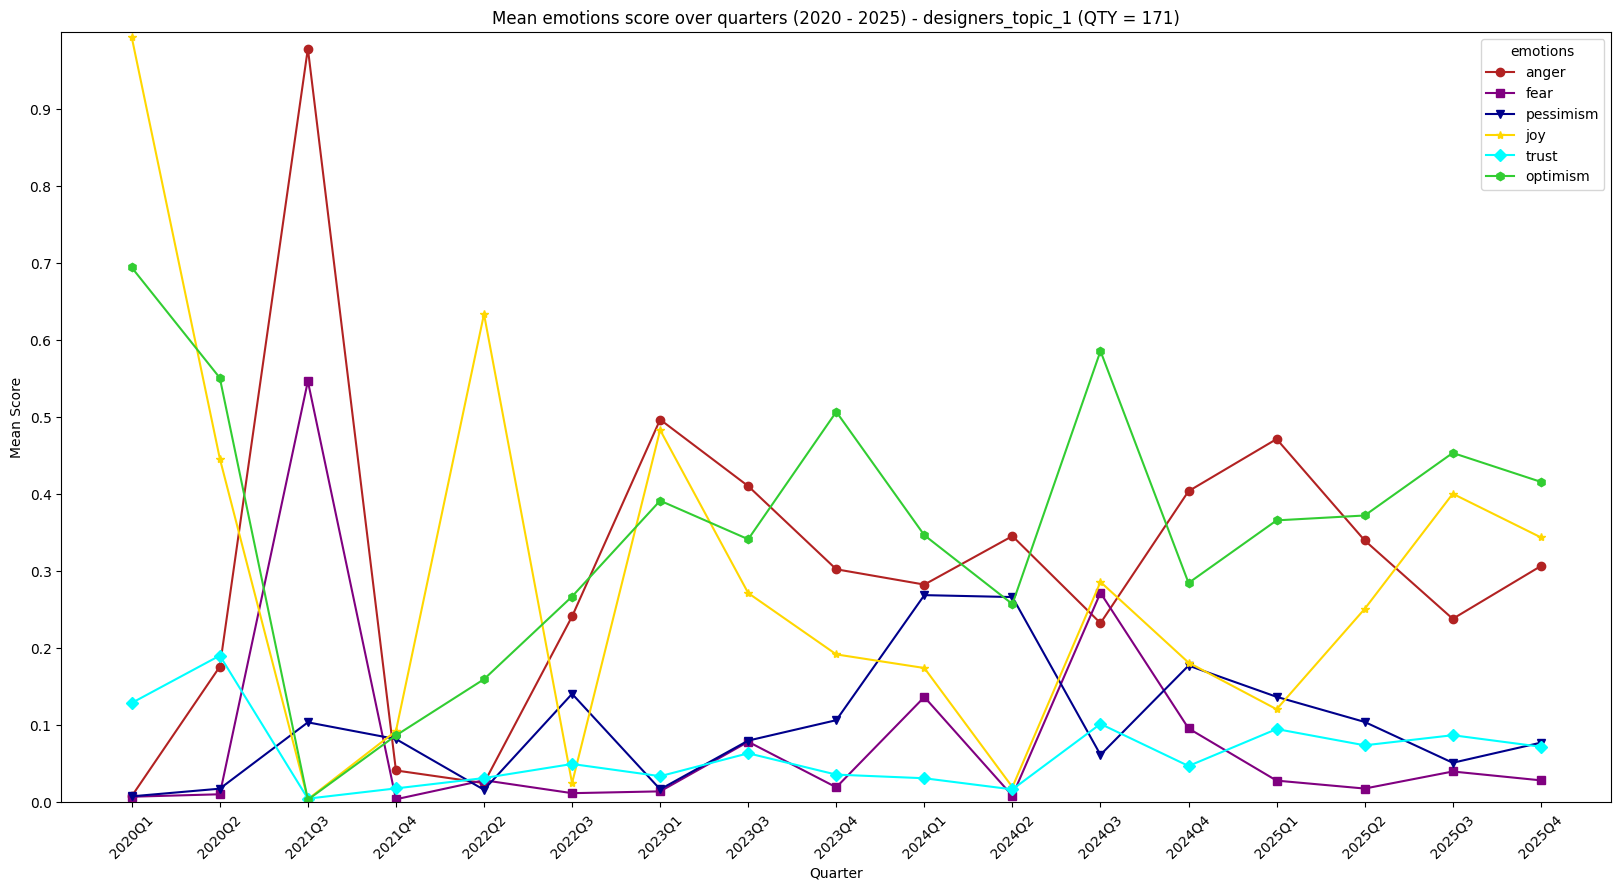

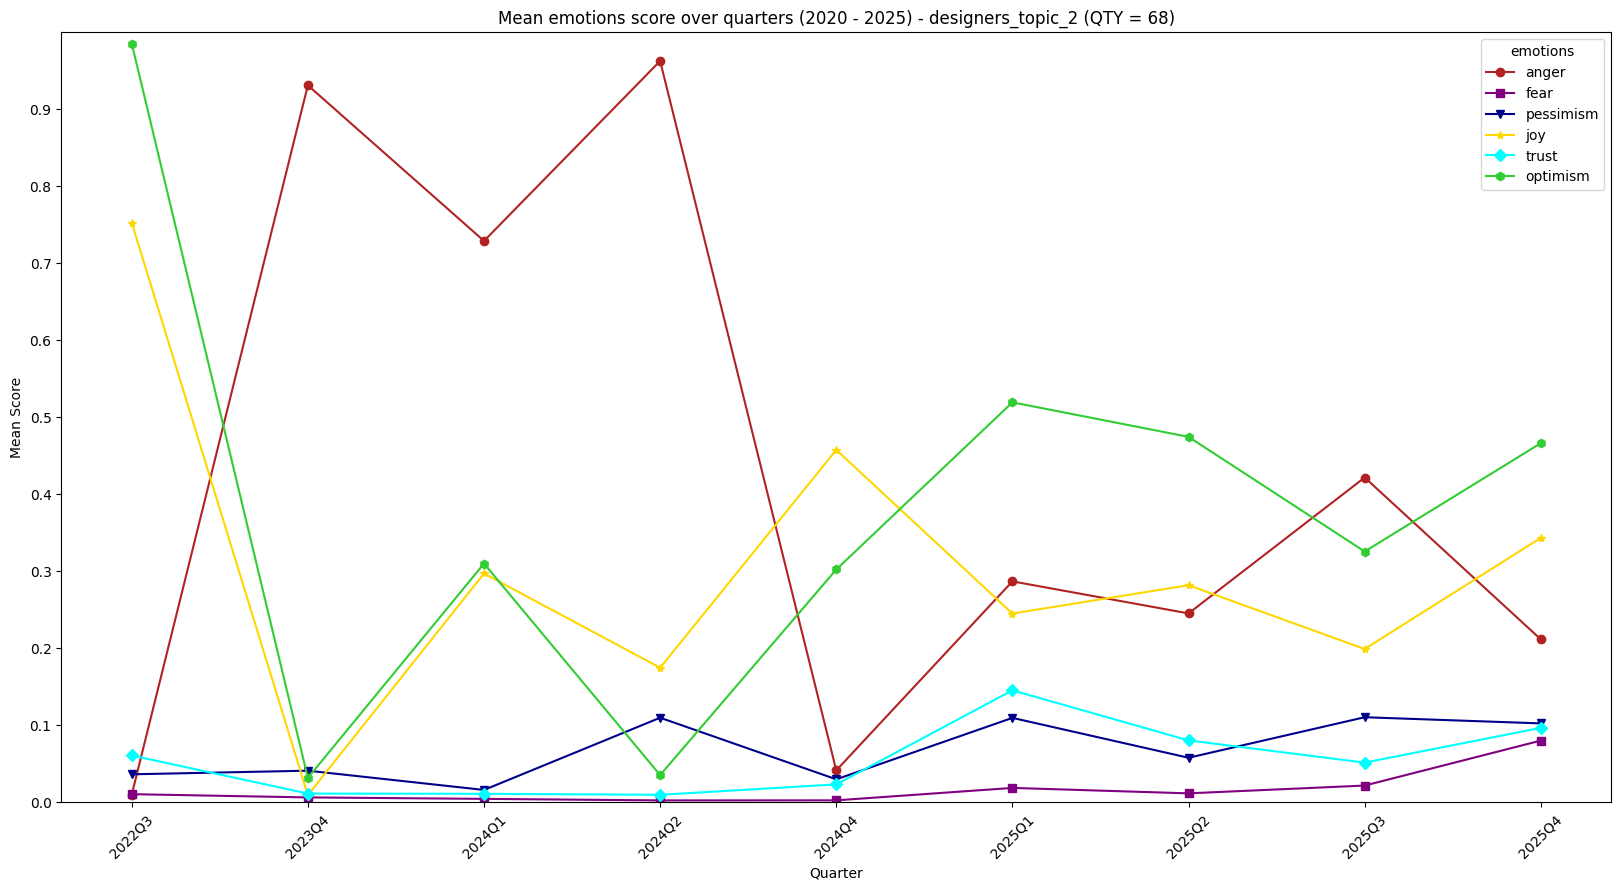

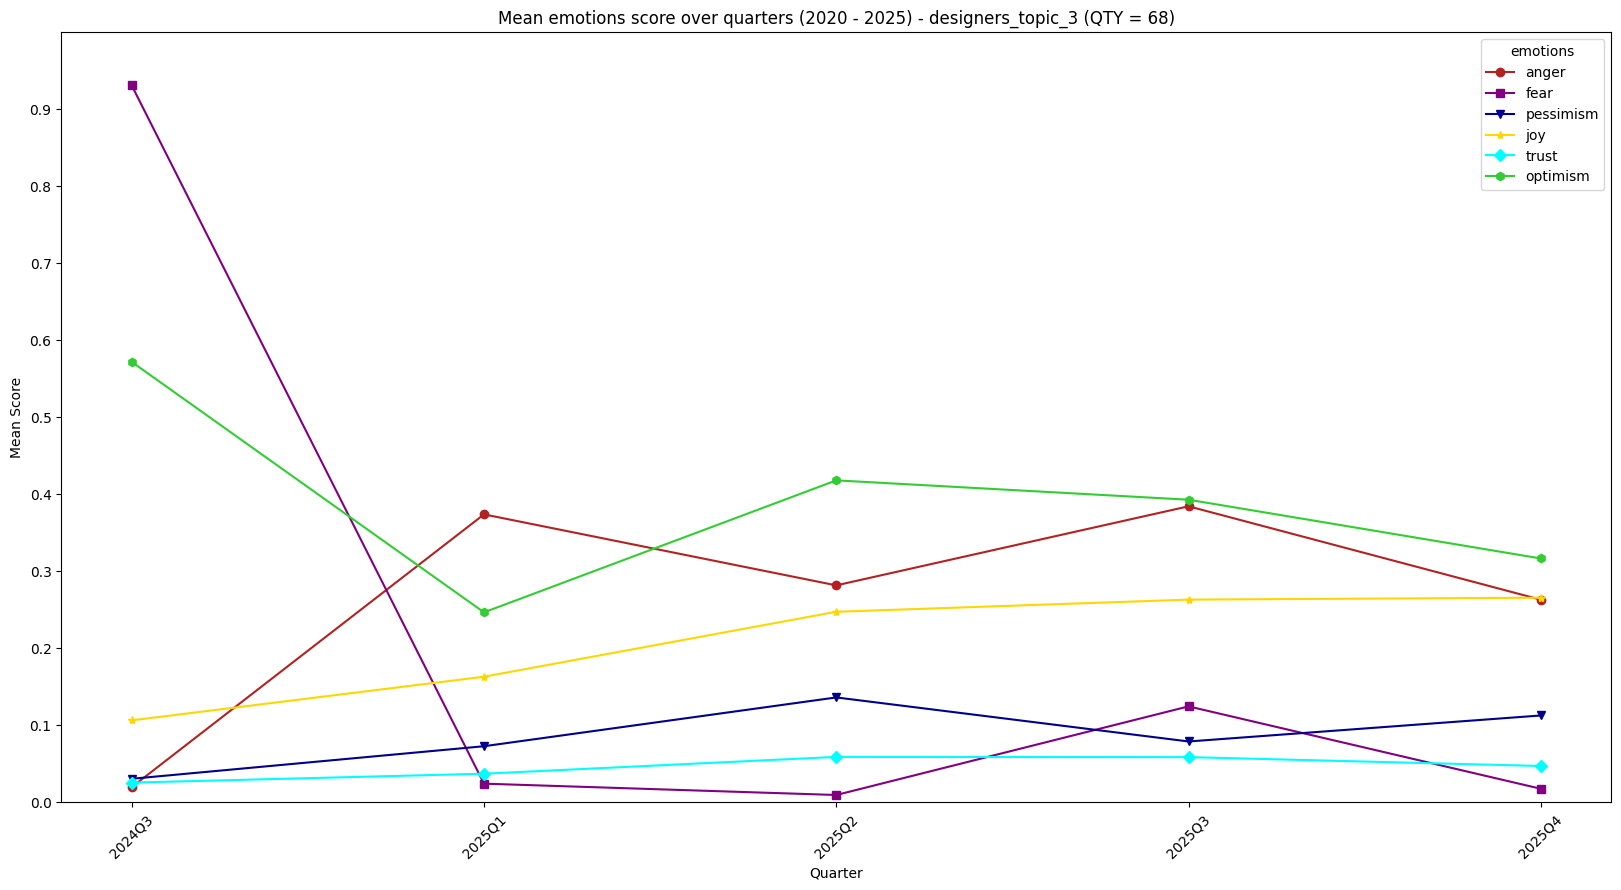

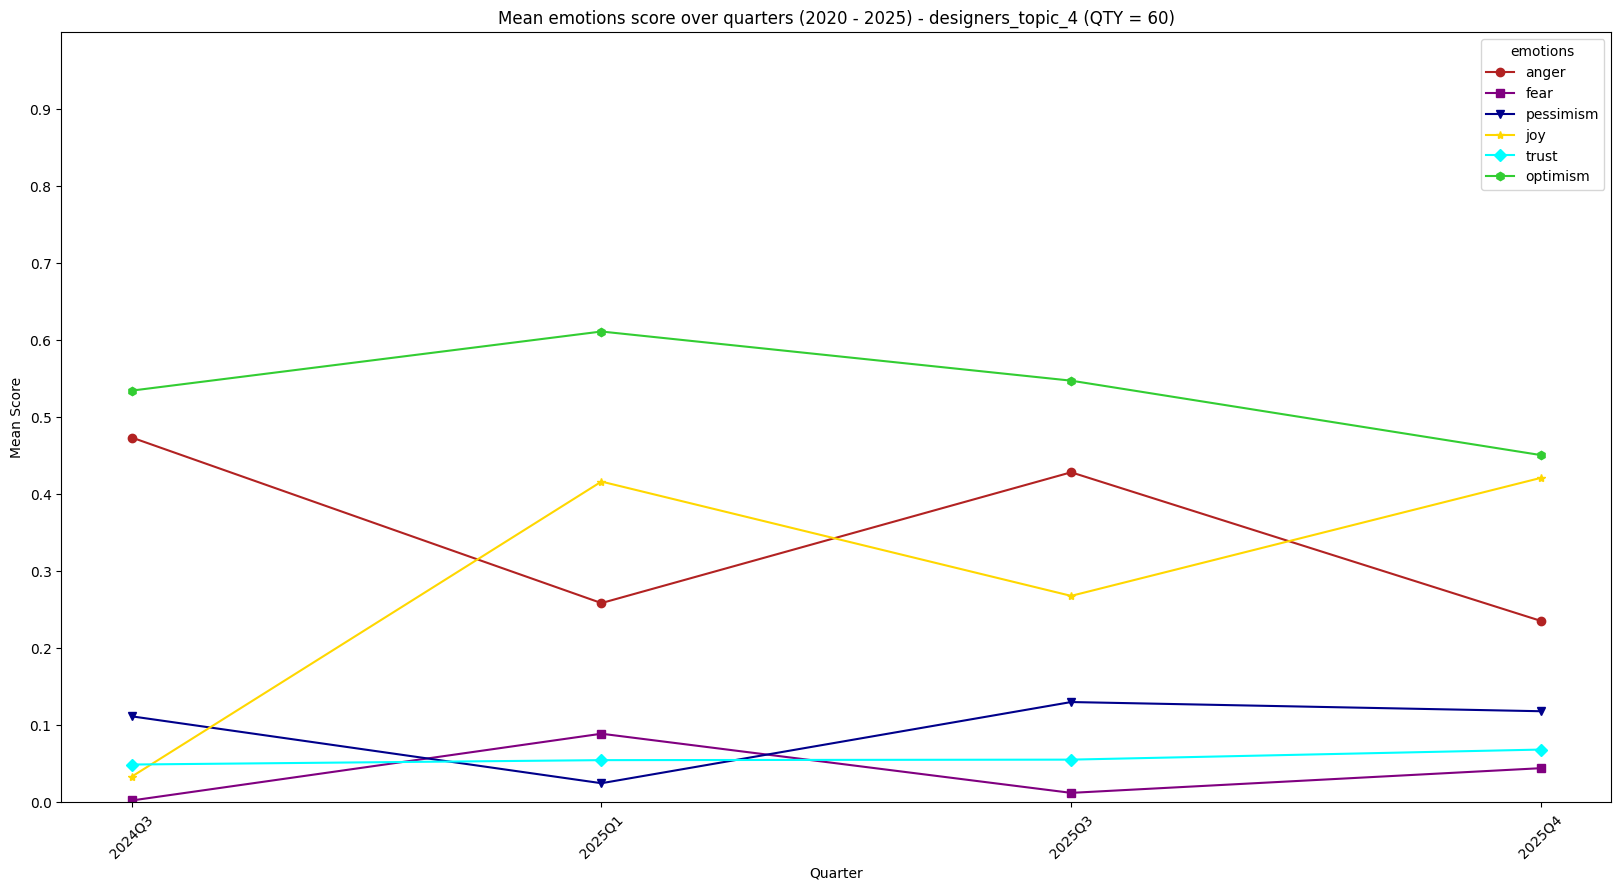

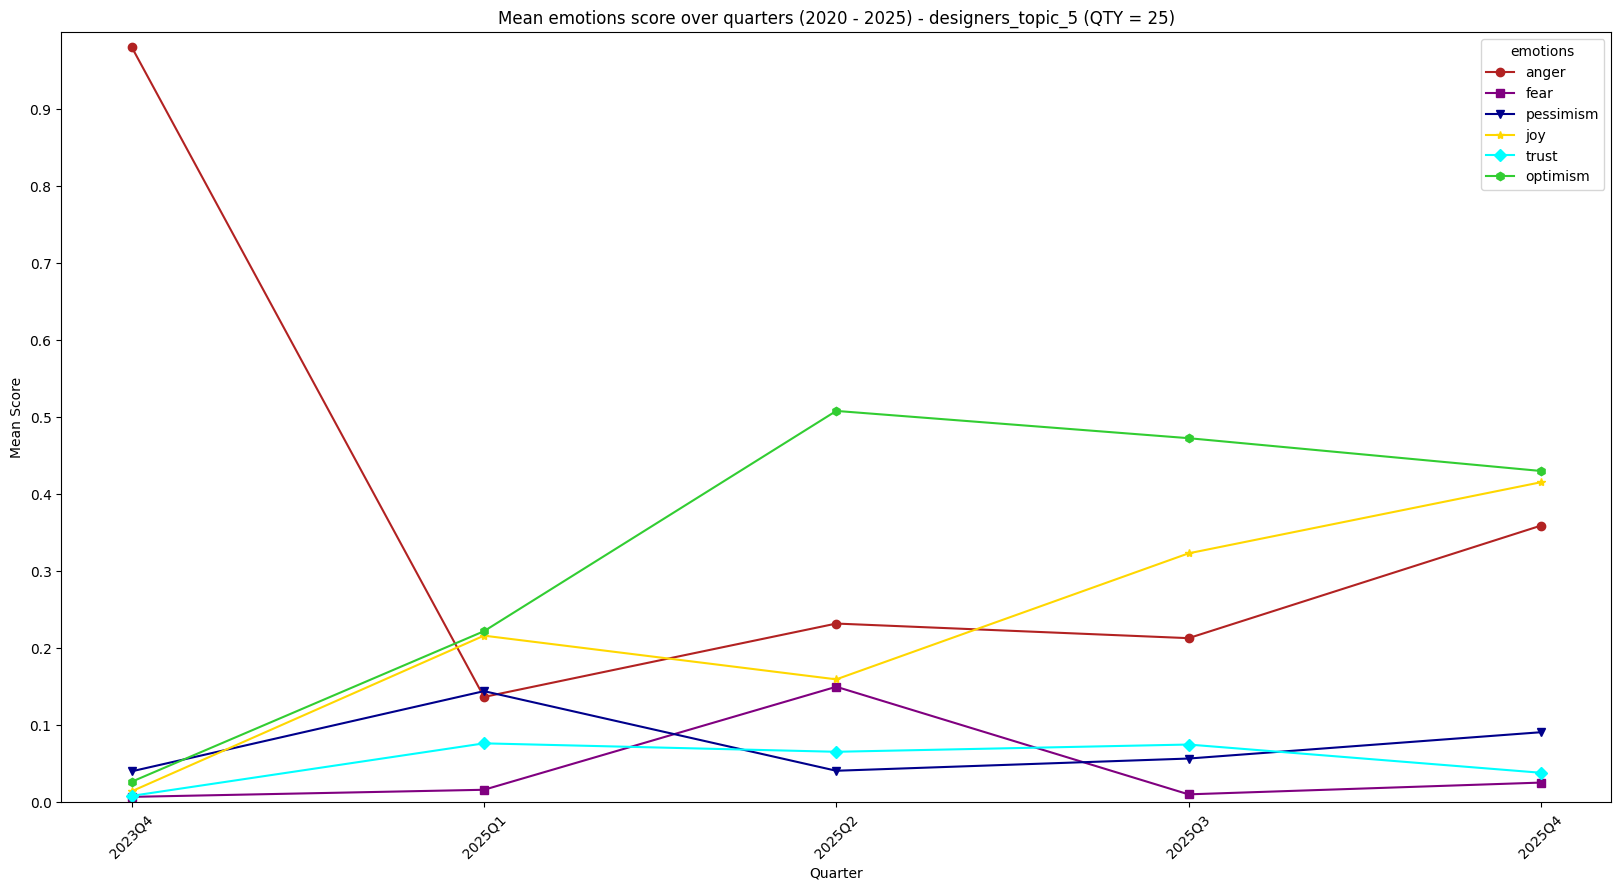

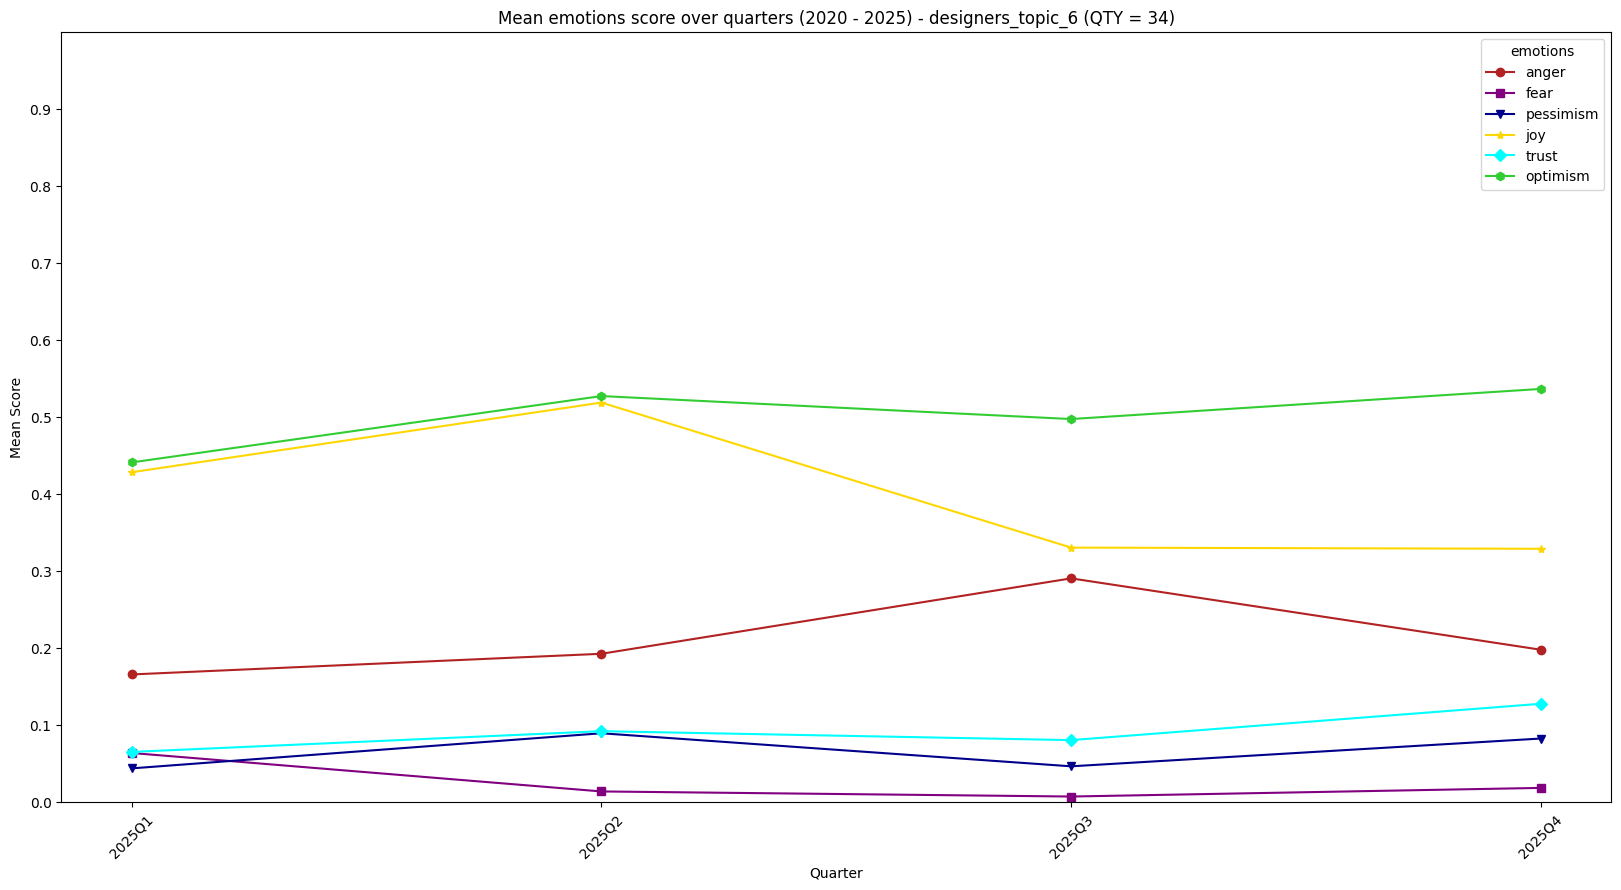

In [ ]:
if not os.path.exists(f"{BERT_topics_address}/designers_plots"):
    os.makedirs(f"{BERT_topics_address}/designers_plots")

n_topics = designers_topics.shape[1]-1

for t in range(n_topics):
  # obtain documents related to the topic
  topic_comments_indexes = designers_topics[designers_topics[f'cluster_{t}'] == 1].index.values.astype(int)
  topic_comments = designers_comments.iloc[topic_comments_indexes]
  qty = topic_comments.shape[0]
  # calculate emotion means for the specific topic
  topic_emotion_means = emotions_means(topic_comments, possible_emotions, 'Q', False)
  plot_emotions(f"{BERT_topics_address}/designers_plots", topic_emotion_means, possible_emotions, f"designers_topic_{t}", colors, markers, extra = f" (QTY = {qty})")


In [ ]:
if not os.path.exists(f"{BERT_topics_address}/programmers_plots"):
    os.makedirs(f"{BERT_topics_address}/programmers_plots")

n_topics = programmers_topics.shape[1]-1

for t in range(n_topics):
  # obtain documents related to the topic
  topic_comments_indexes = programmers_topics[programmers_topics[f'cluster_{t}'] == 1].index.values.astype(int)
  topic_comments = programmers_comments.iloc[topic_comments_indexes]
  qty = topic_comments.shape[0]
  # calculate emotion means for the specific topic
  topic_emotion_means = emotions_means(topic_comments, possible_emotions, 'Q', False)
  plot_emotions(f"{BERT_topics_address}/programmers_plots", topic_emotion_means, possible_emotions, f"programmers_topic_{t}", colors, markers, extra = f" (QTY = {qty})")


## Topics from Louvain

In [ ]:
designers_topics = pd.read_csv(f"{louvain_topics_address}/C_designers.csv")
programmers_topics = pd.read_csv(f"{louvain_topics_address}/C_programmers.csv")

print(f"Designers topics: {designers_topics.shape[1]}")
print(f"Programmers topics: {programmers_topics.shape[1]}")

Designers topics: 9
Programmers topics: 6


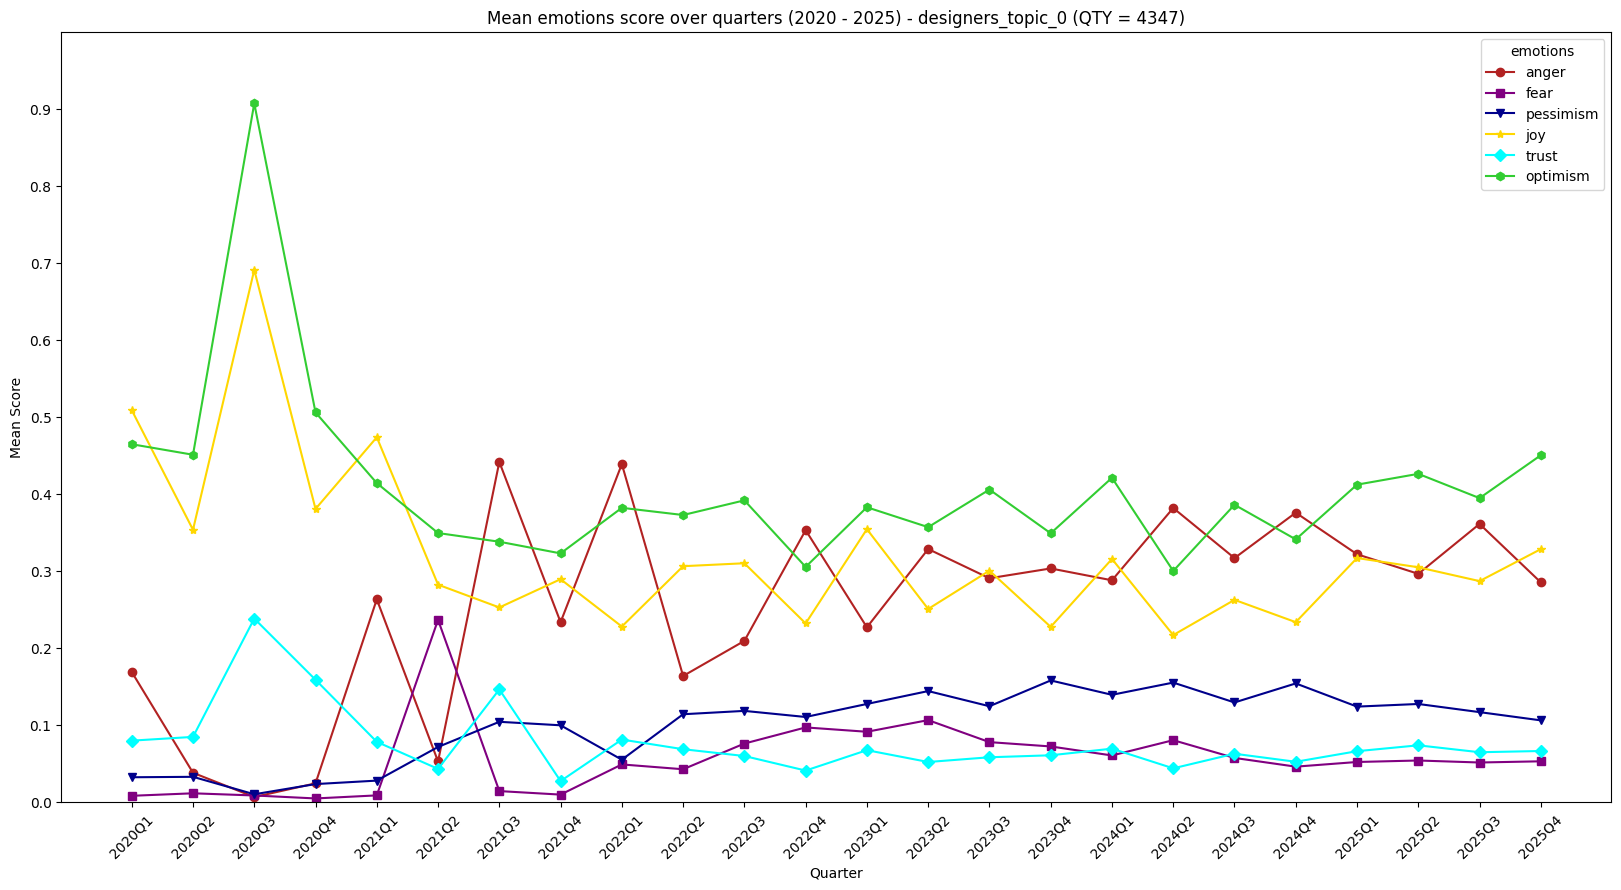

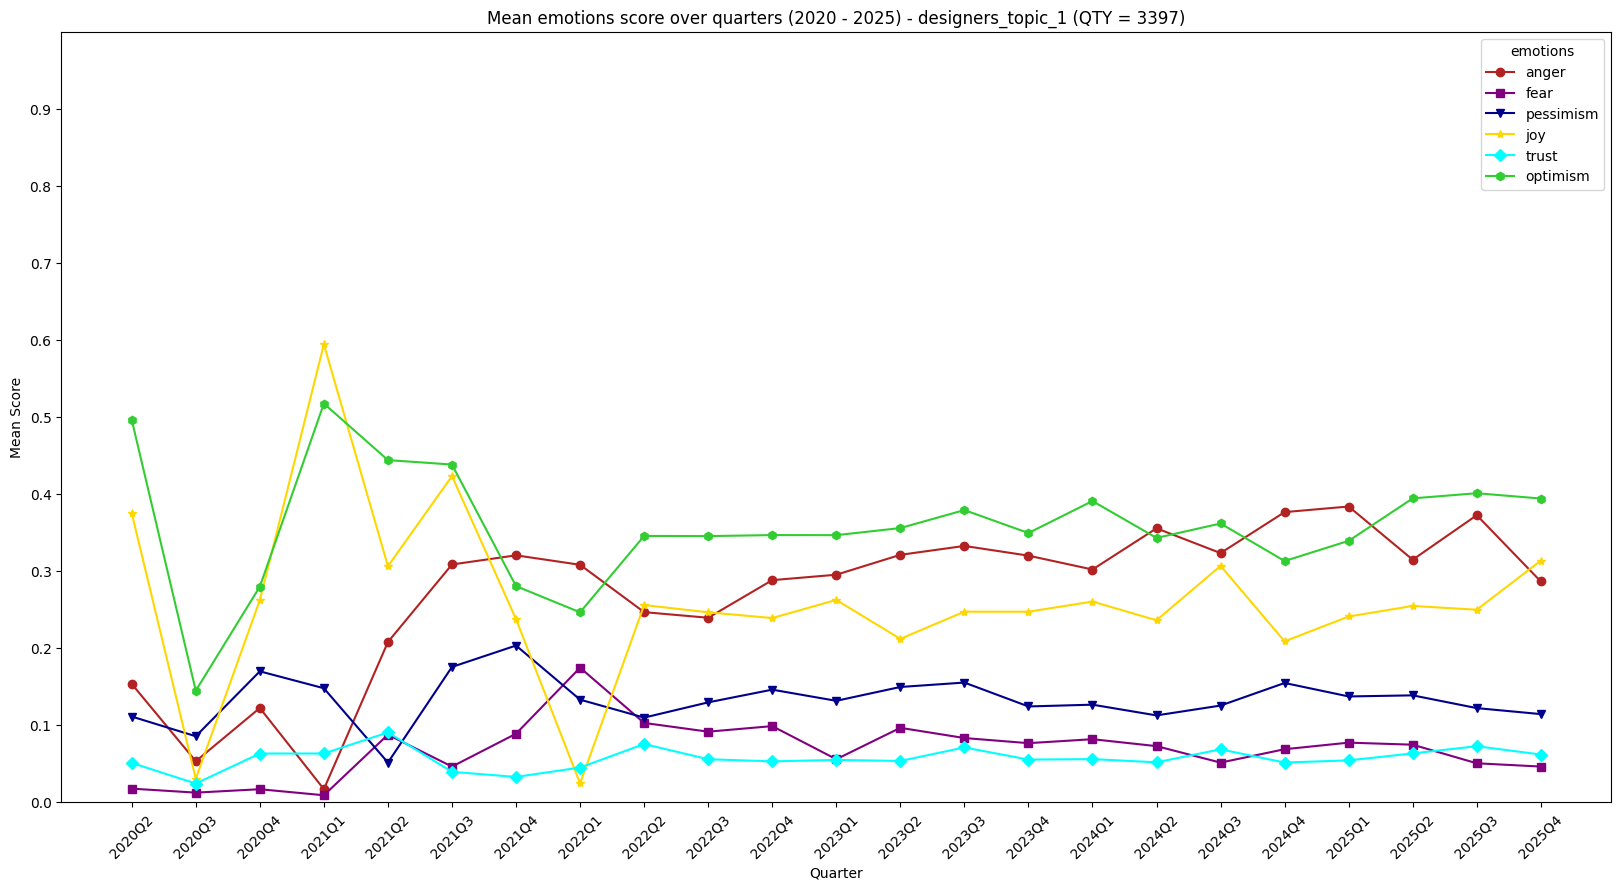

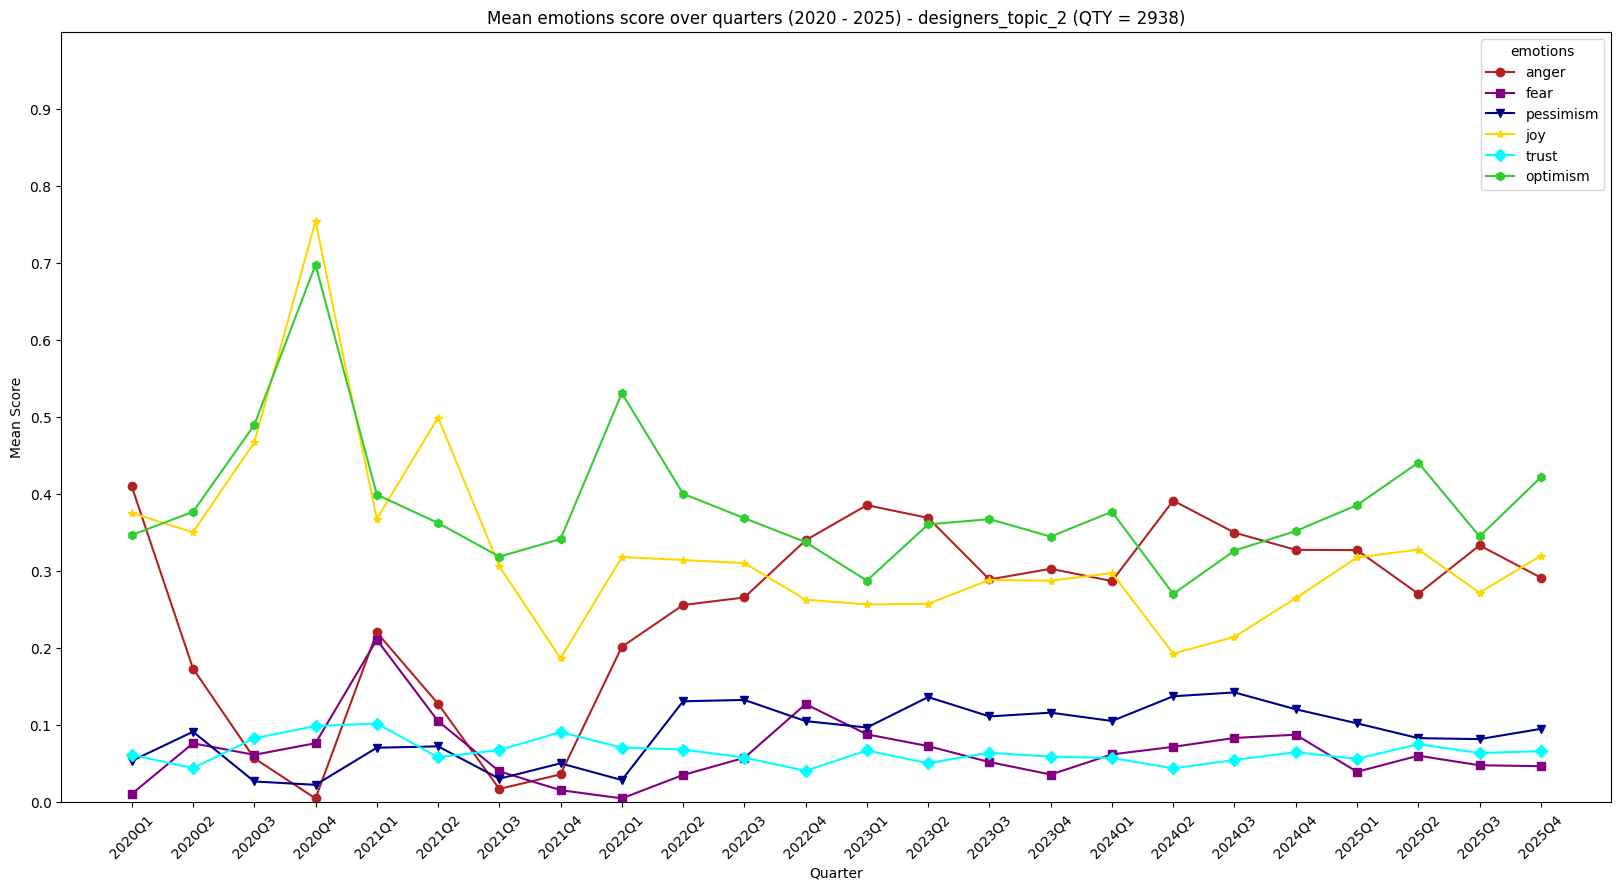

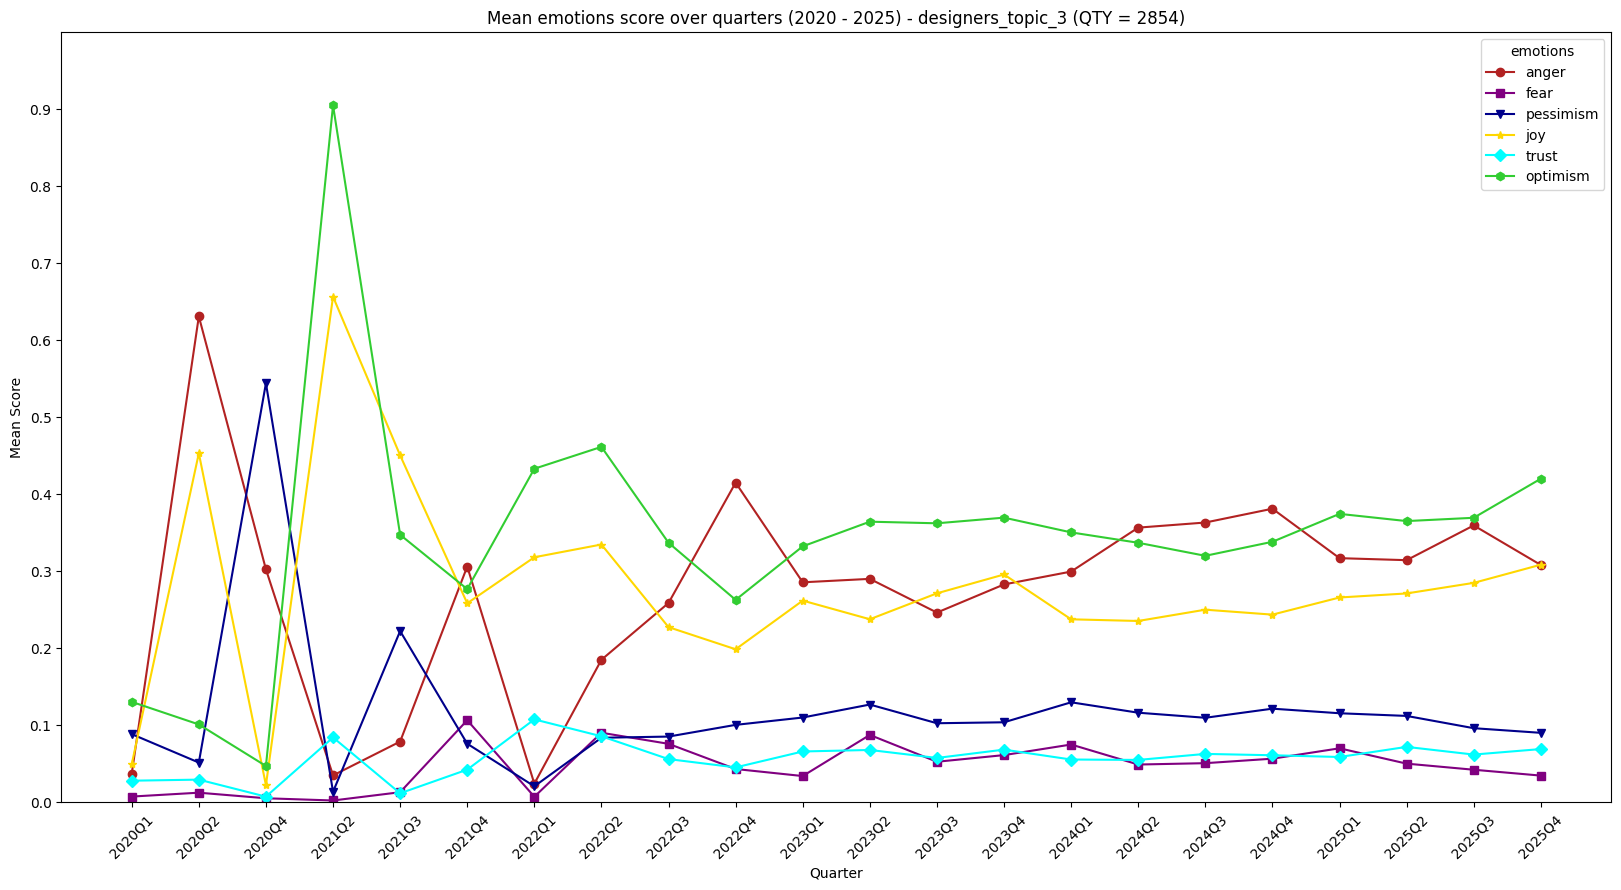

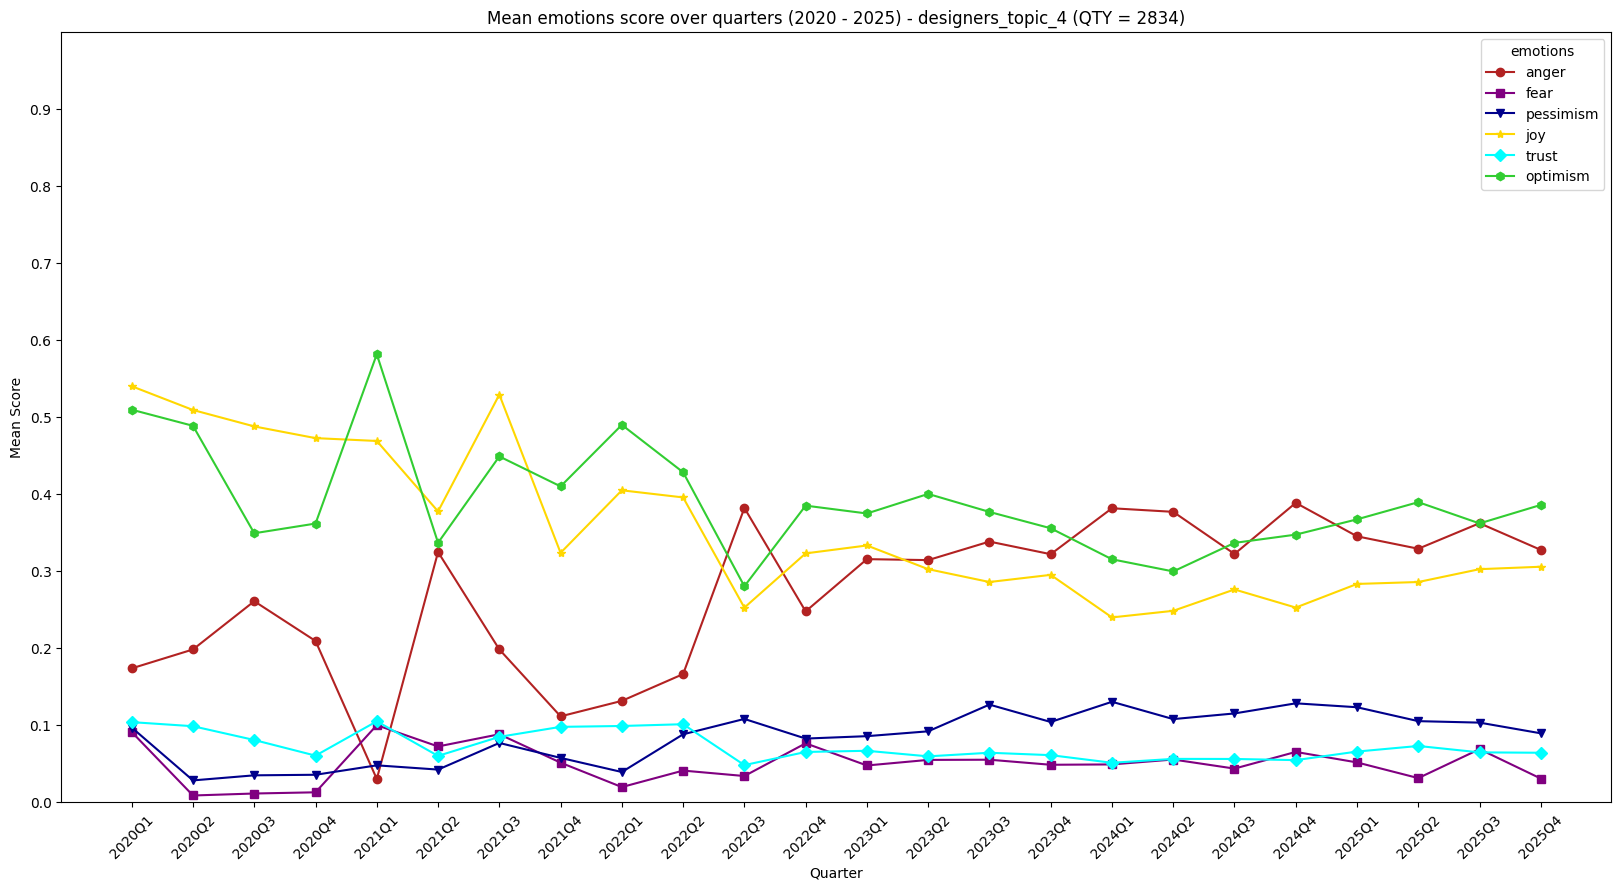

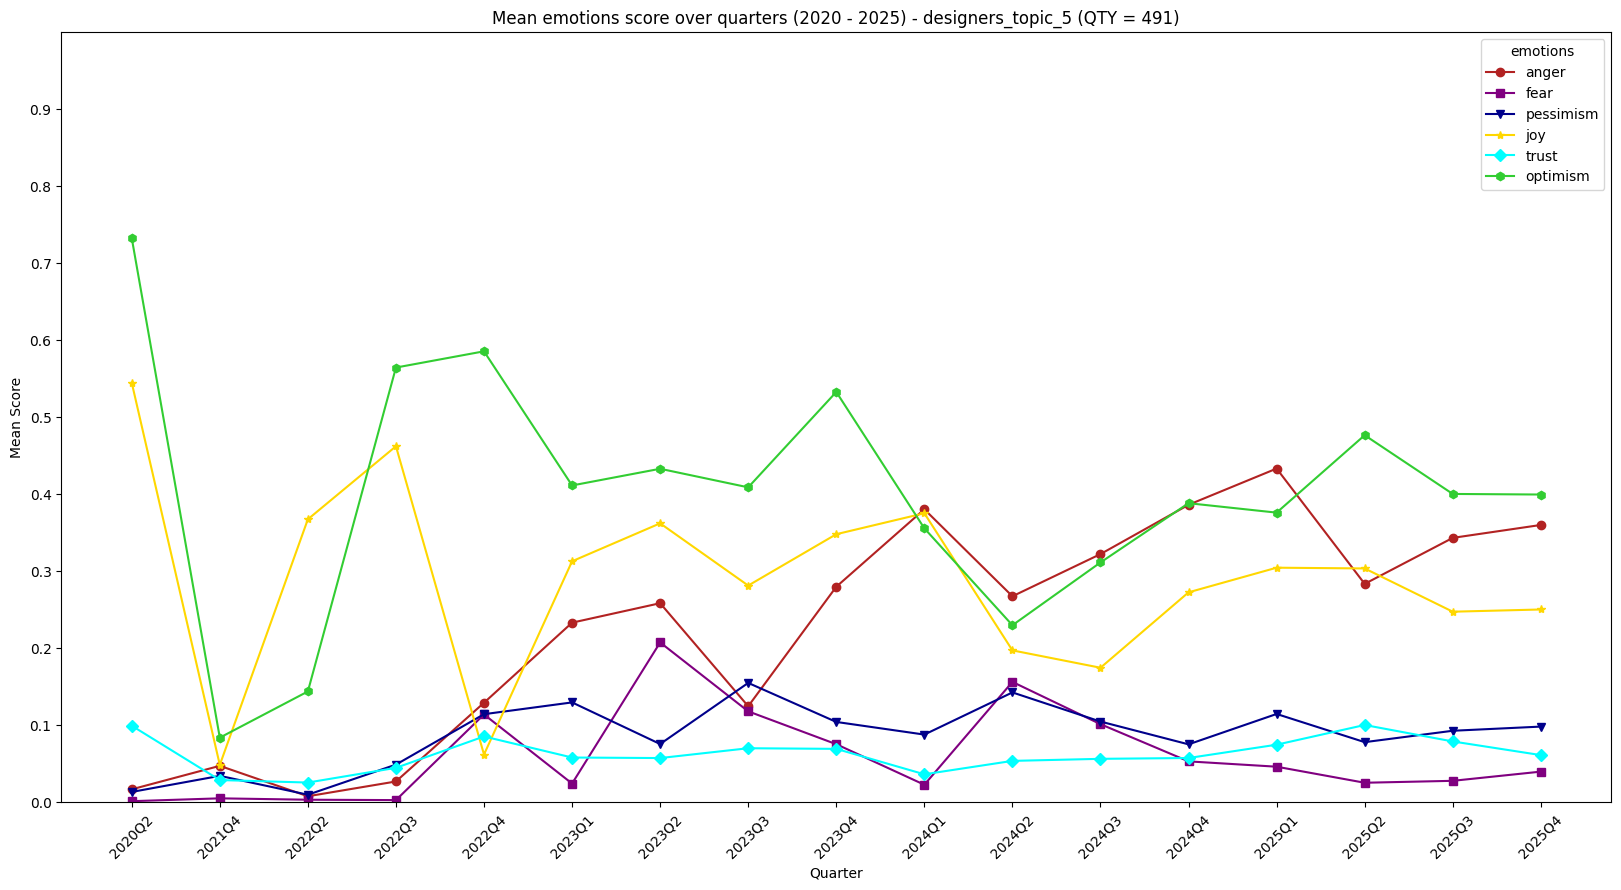

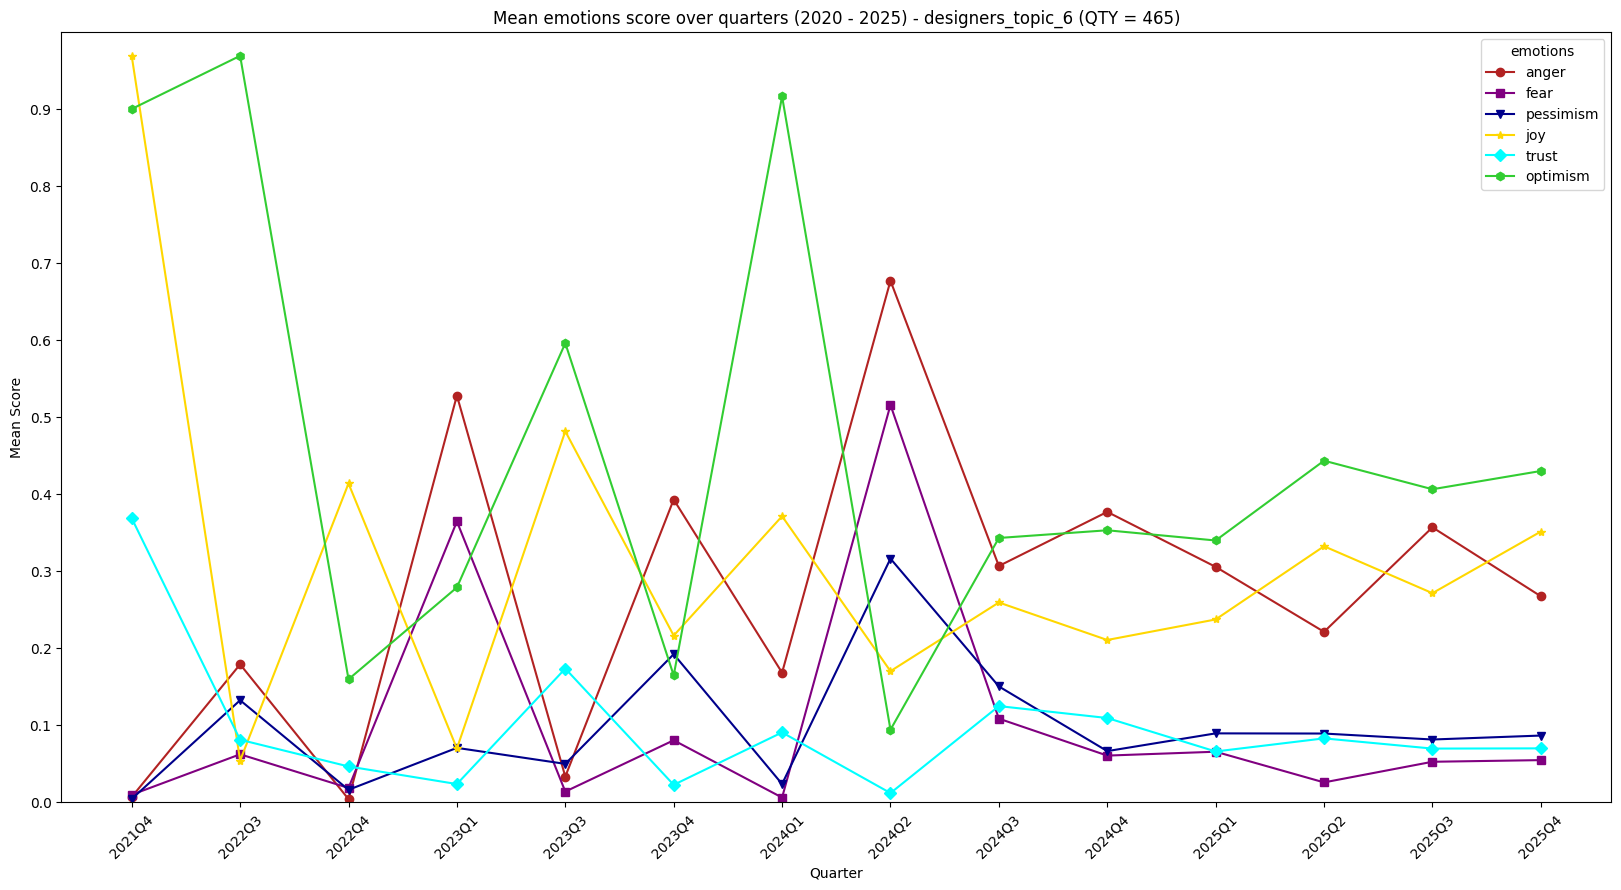

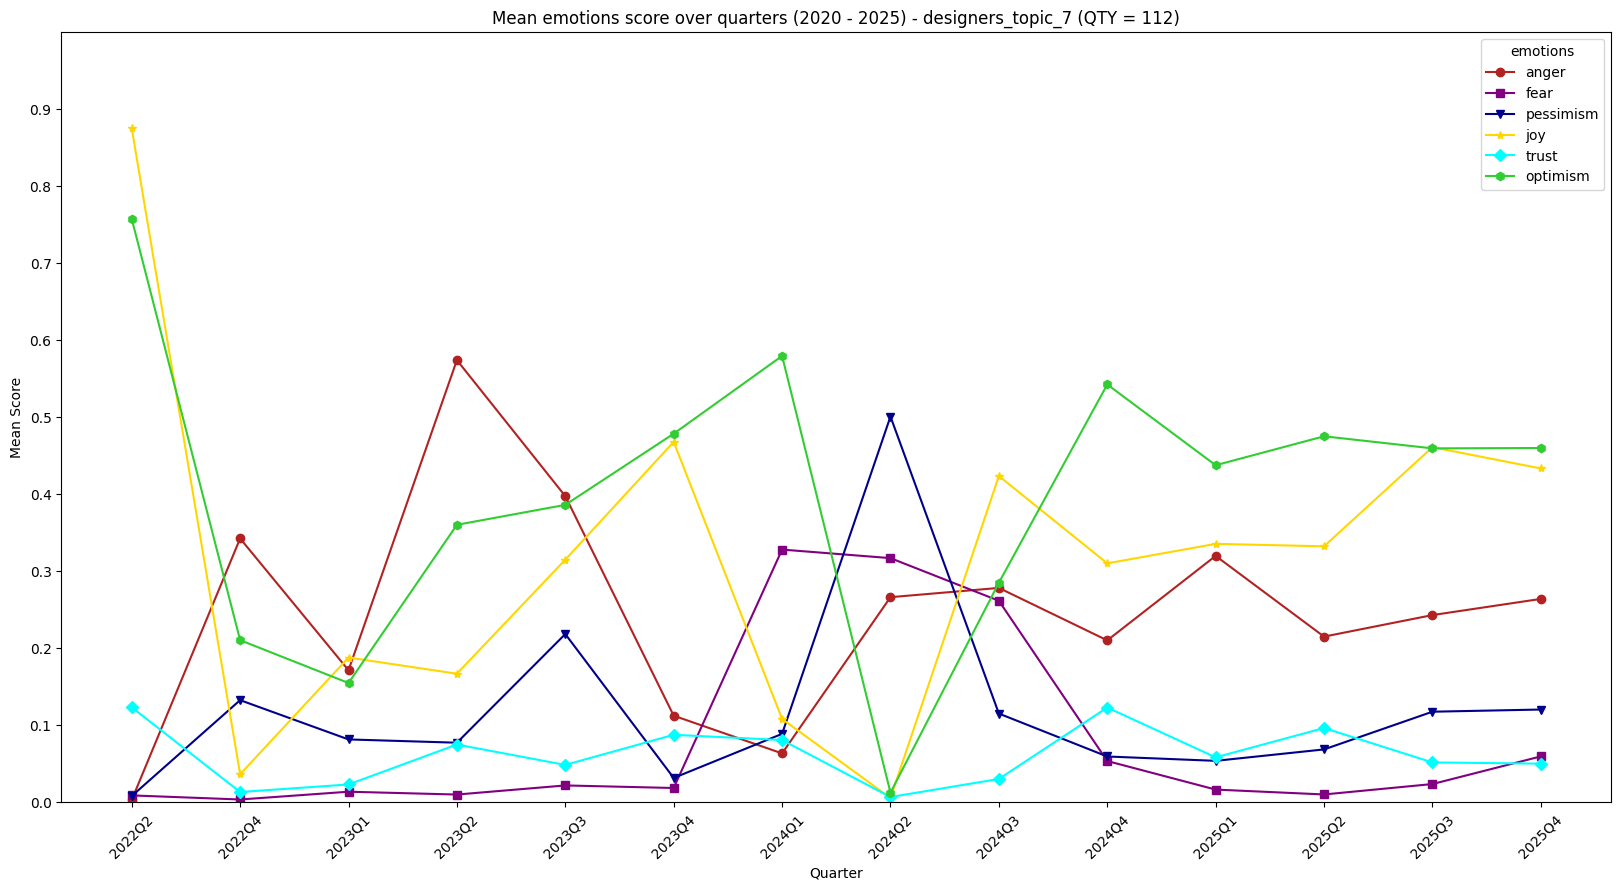

In [ ]:
if not os.path.exists(f"{louvain_topics_address}/designers_plots"):
    os.makedirs(f"{louvain_topics_address}/designers_plots")

n_topics = designers_topics.shape[1]-1

for t in range(n_topics):
  # obtain documents related to the topic
  topic_comments_indexes = designers_topics[designers_topics[f'cluster_{t}'] == 1].index.values.astype(int)
  topic_comments = designers_comments.iloc[topic_comments_indexes]
  qty = topic_comments.shape[0]
  # calculate emotion means for the specific topic
  topic_emotion_means = emotions_means(topic_comments, possible_emotions, 'Q', False)
  plot_emotions(f"{louvain_topics_address}/designers_plots", topic_emotion_means, possible_emotions, f"designers_topic_{t}", colors, markers, extra = f" (QTY = {qty})")

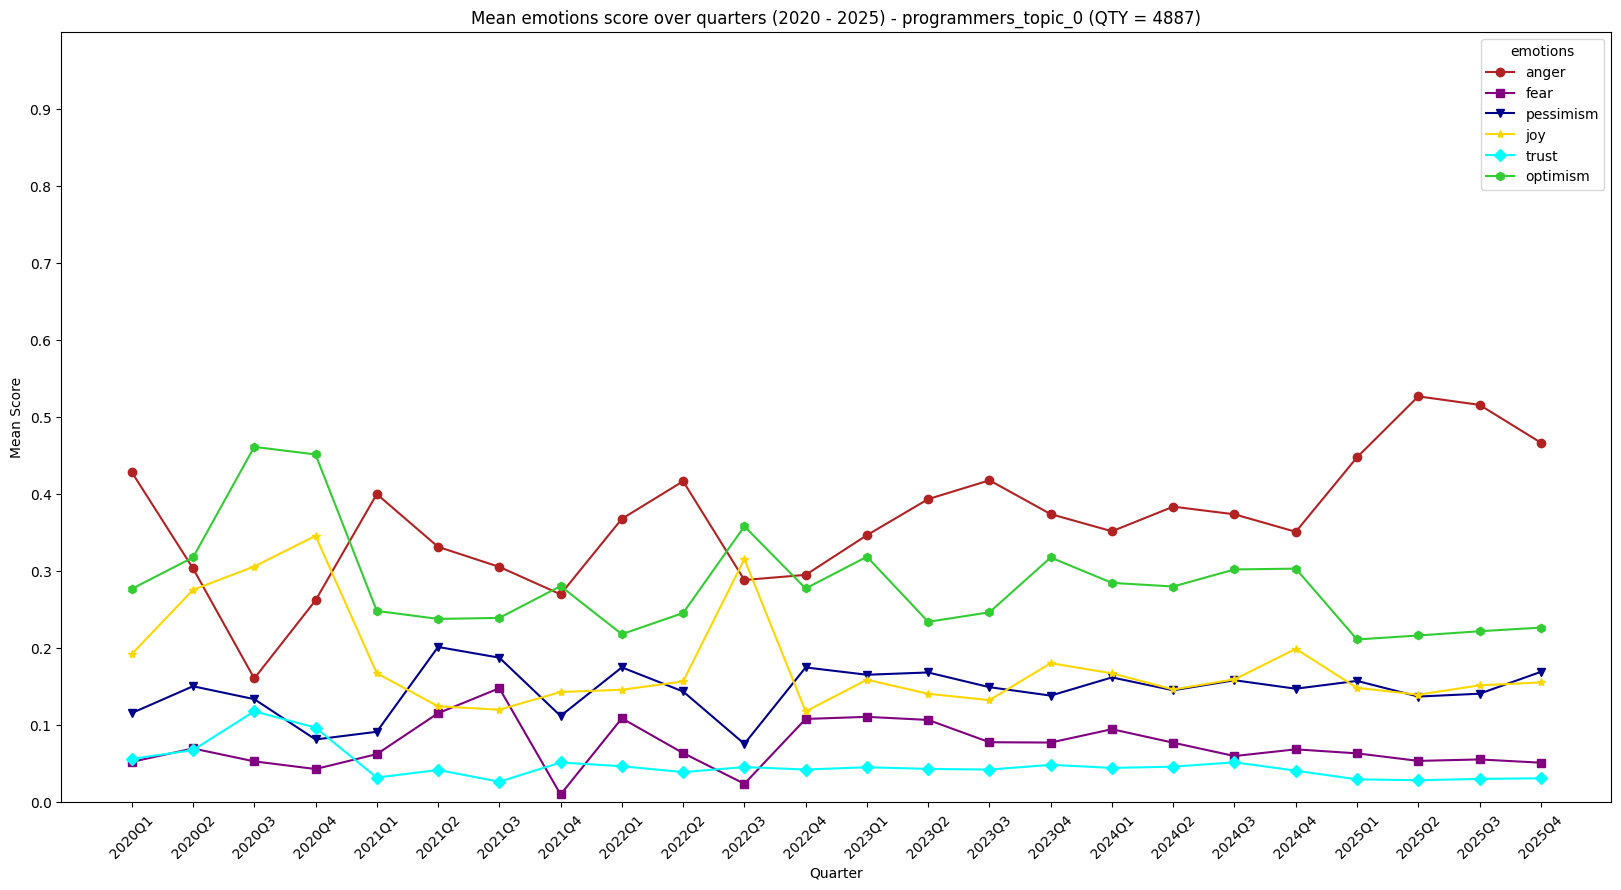

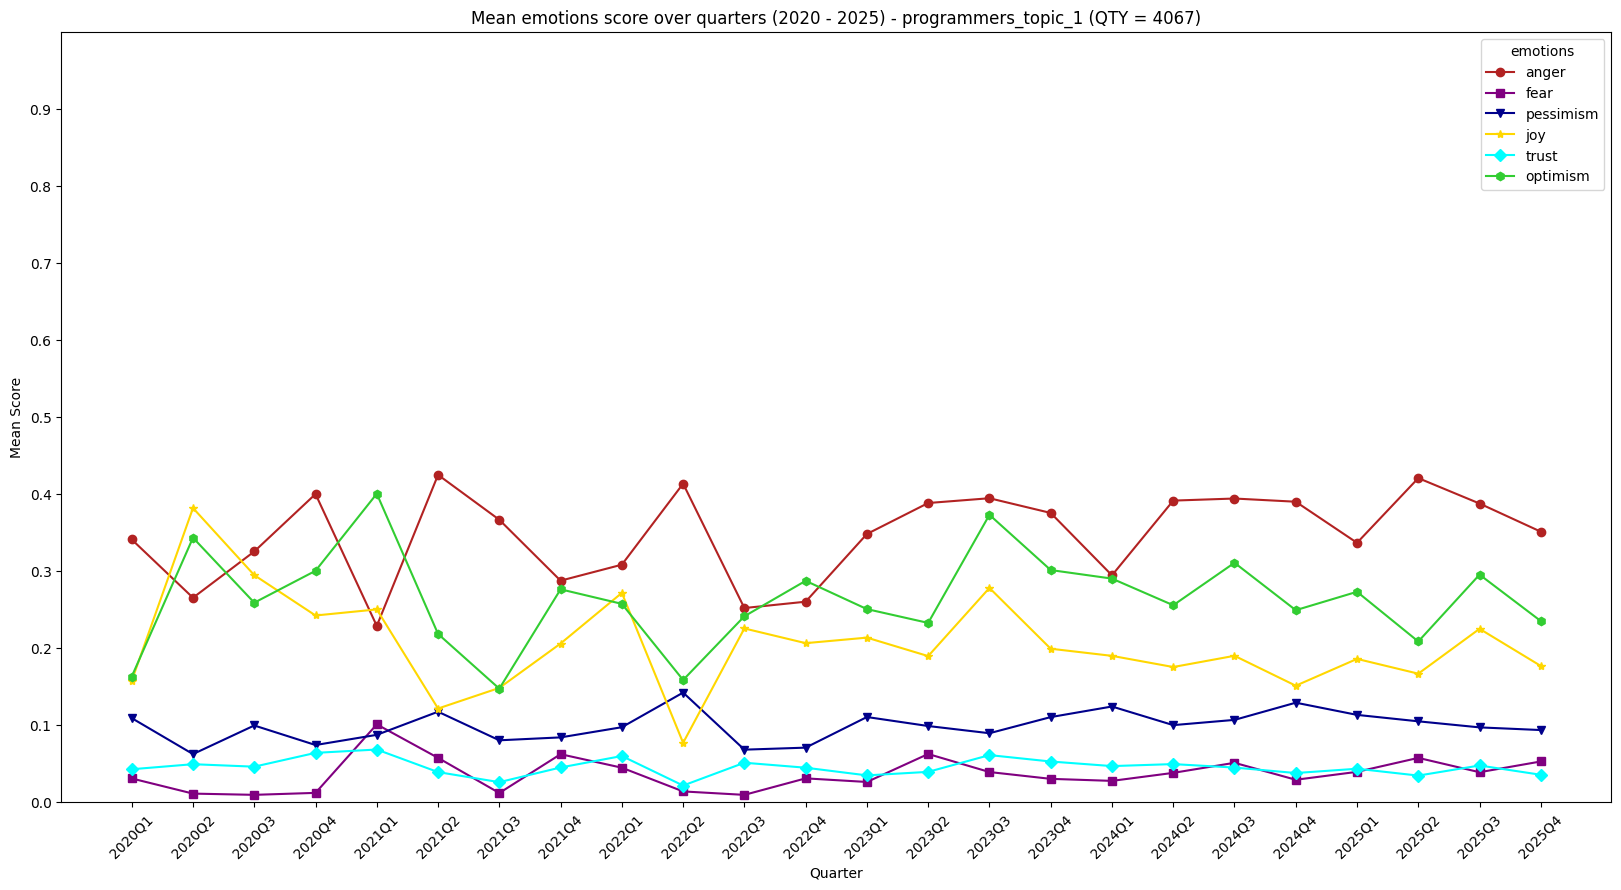

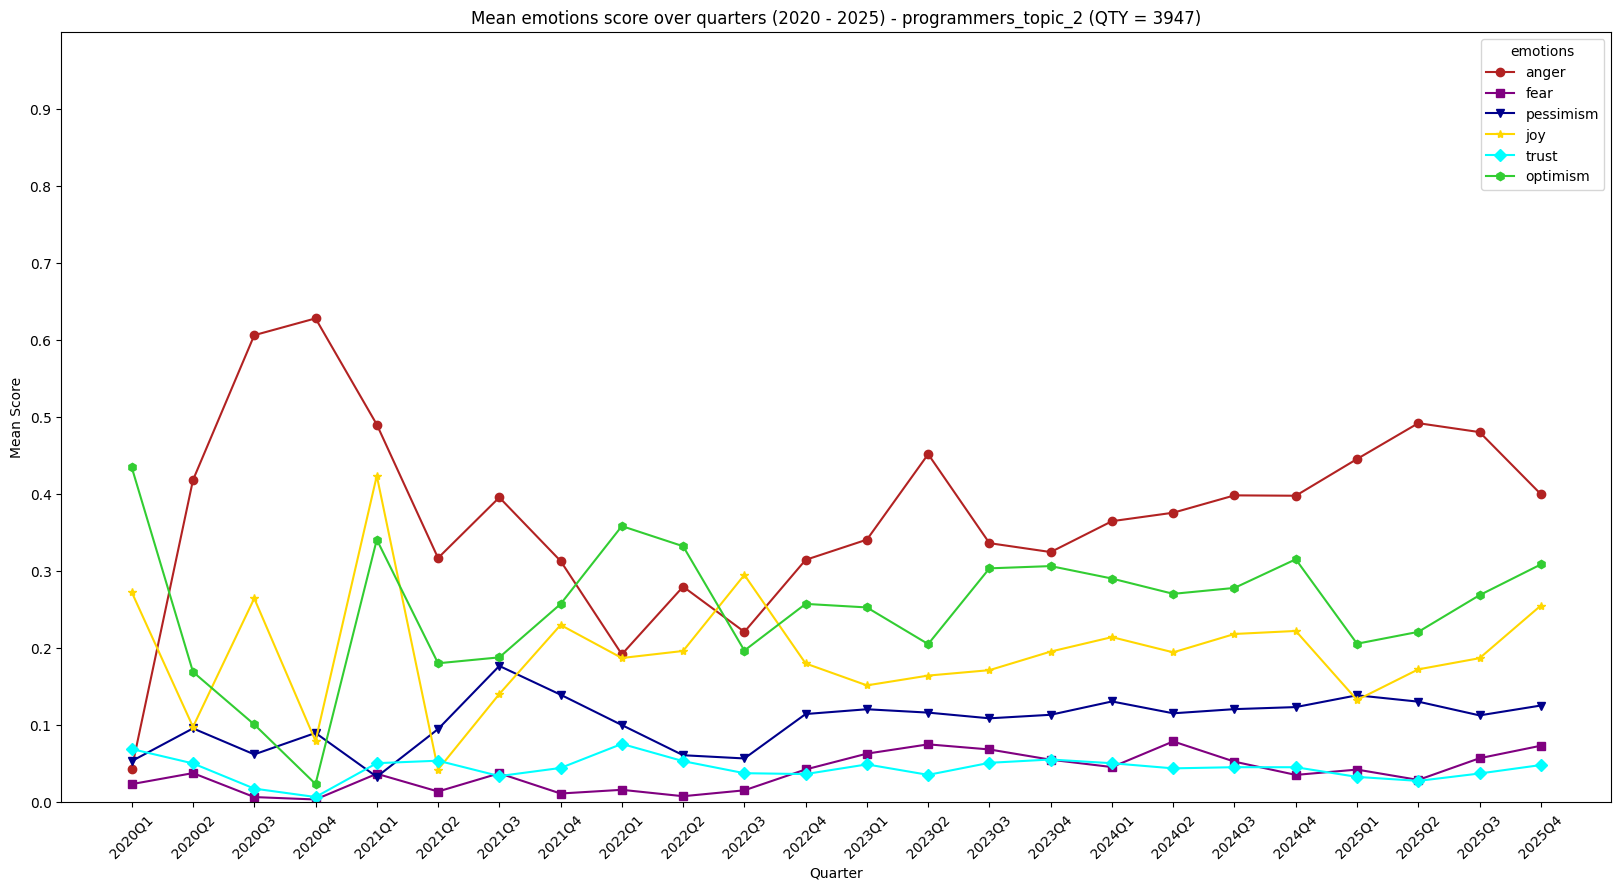

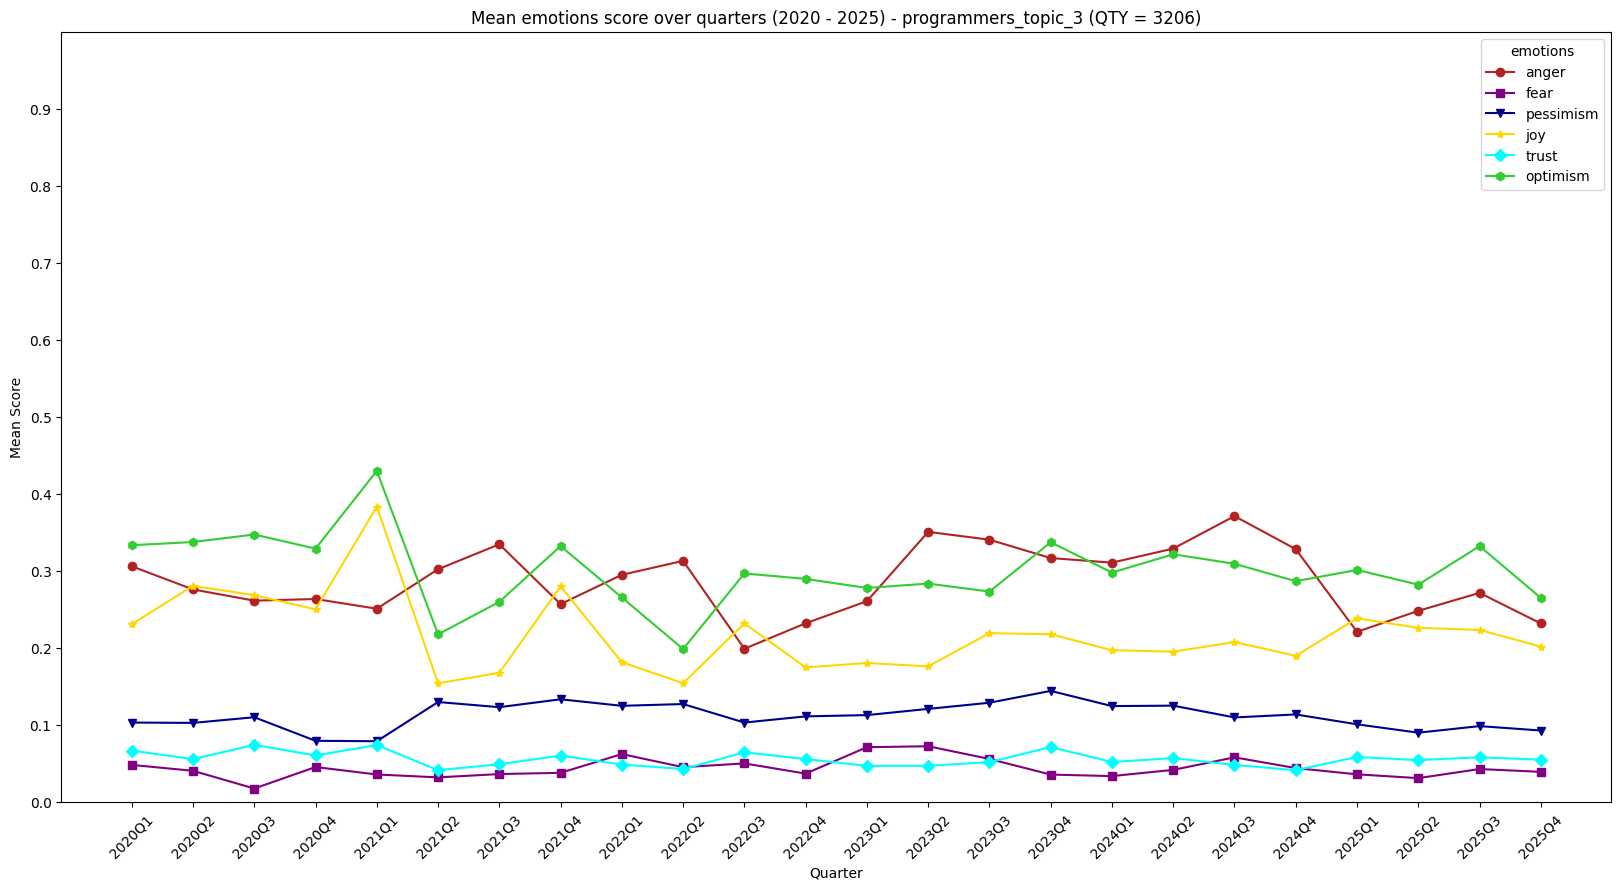

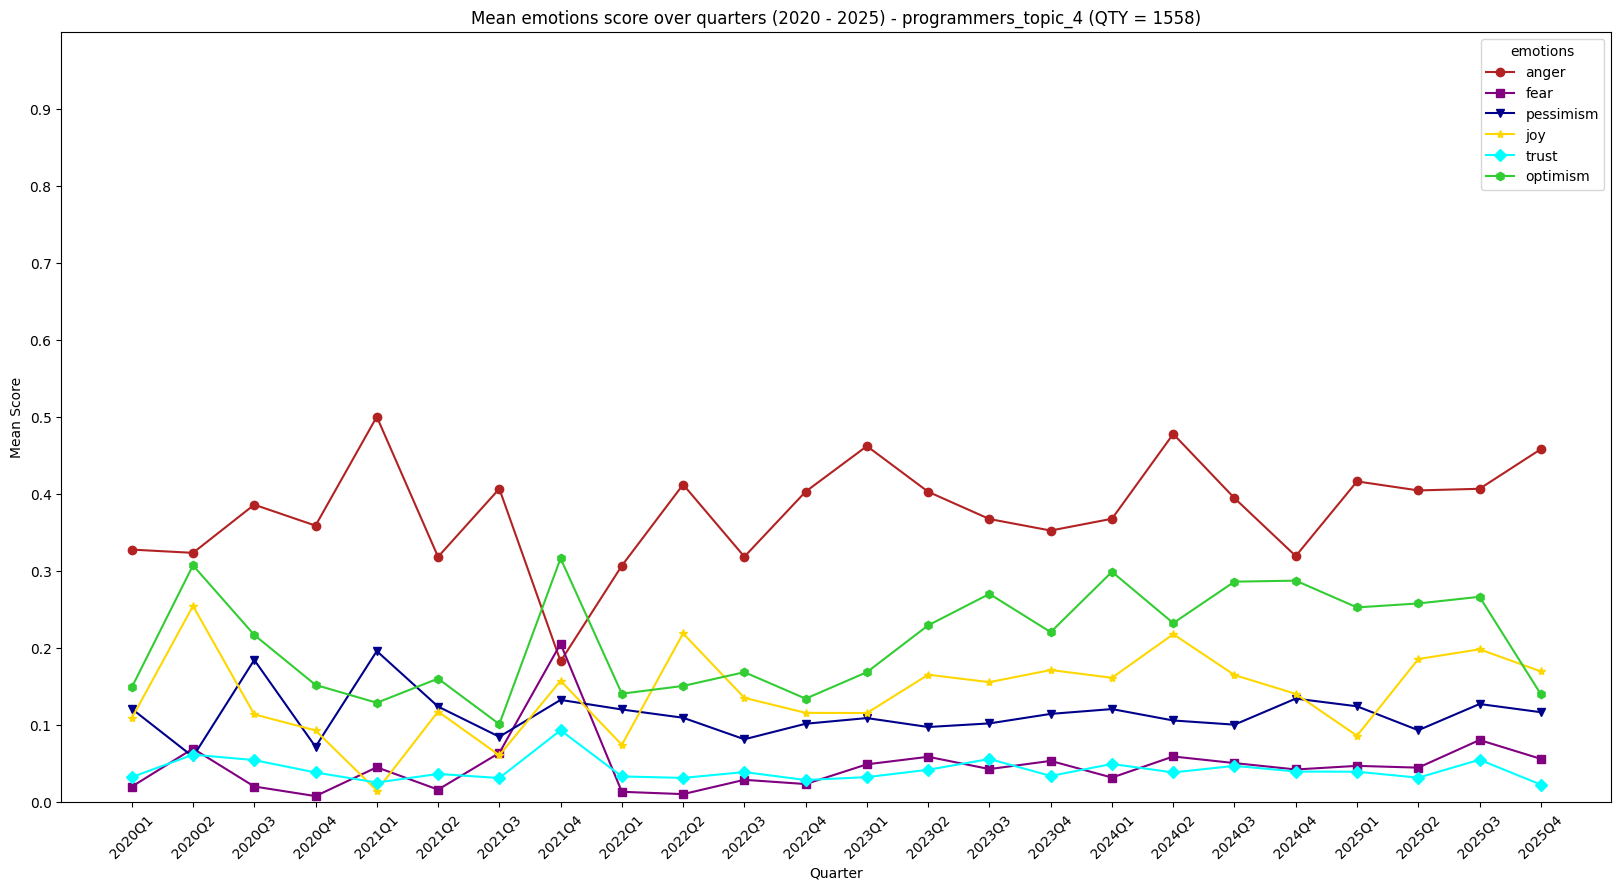

In [ ]:
if not os.path.exists(f"{louvain_topics_address}/programmers_plots"):
    os.makedirs(f"{louvain_topics_address}/programmers_plots")

n_topics = programmers_topics.shape[1]-1

for t in range(n_topics):
  # obtain documents related to the topic
  topic_comments_indexes = programmers_topics[programmers_topics[f'cluster_{t}'] == 1].index.values.astype(int)
  topic_comments = programmers_comments.iloc[topic_comments_indexes]
  qty = topic_comments.shape[0]
  # calculate emotion means for the specific topic
  topic_emotion_means = emotions_means(topic_comments, possible_emotions, 'Q', False)
  plot_emotions(f"{louvain_topics_address}/programmers_plots", topic_emotion_means, possible_emotions, f"programmers_topic_{t}", colors, markers, extra = f" (QTY = {qty})")
